# Autonomous AI Research Agent — AI that Summarizes Research Papers
**Final Capstone Project** · LangChain · RAG · LangGraph multi-agent system · FAISS · Streamlit

---

## 1. Problem statement

Researchers, students and analysts cannot keep up with the volume of new papers. Reading a 10–20 page paper takes 30–60 minutes, and a plain LLM prompt is a poor substitute:

* **Context limits** – a full paper often exceeds the model's context window, so naive truncation drops the results and limitations sections.
* **Hallucination** – abstractive summaries invent numbers, datasets and claims.
* **No critique** – a summary says *what* a paper claims, not *how well* it supports it.
* **No follow-up** – readers need to ask questions and compare several papers.

**Objective.** Build an *autonomous* research agent that, given one or more papers — PDF, Word, PowerPoint, Excel/CSV or text files — or arXiv IDs:

1. ingests and indexes the papers (PDF → chunks → embeddings → FAISS),
2. plans what to look for and retrieves evidence (**Research Agent**),
3. writes a structured, citation-grounded summary (**Summarizer Agent**),
4. checks its own work and revises when quality is low (**Reviewer Agent** – self-reflection loop),
5. critiques the paper and compares papers (**Analyst Agent**),
6. writes an executive brief with recommendations and exports it as a PDF (**Report Writer Agent**),
7. answers follow-up questions with conversational memory and source citations (**Q&A Agent**).

The agents are orchestrated as a **LangGraph state machine** with a conditional loop, and the same code powers the Streamlit app (`autonomous_research_agent.py`).

## 2. Setup

### 2.1 How the code is organised

All project code lives in **one file, `autonomous_research_agent.py`**, split into 19 numbered sections. Sections 1–18 are the research agent itself (loading, RAG, agents, report export). Each step of this notebook shows the matching section in full, in the same order, so the section cells are `autonomous_research_agent.py` line for line, up to Section 18. The cells in between (marked *Demo* / *Test*) run and evaluate that code.

Section 19 is the Streamlit web interface. A web app can't run inside a notebook, so it is not repeated here; it lives only in `autonomous_research_agent.py` (see step 12).

The first cell is the top of `autonomous_research_agent.py`: its description and table of contents.

In [136]:
"""
Autonomous AI Research Agent — AI that Summarizes Research Papers
=================================================================
Final Capstone Project · single-file version (all code in this file).

Upload research papers (PDF) or fetch them from arXiv. A team of AI agents —
Research → Summarizer → Reviewer → Analyst → Report Writer, orchestrated with
LangGraph — produces cited summaries, a critical analysis, a cross-paper
comparison and a downloadable report. A chat tab answers follow-up questions
with conversational RAG.

Run the app:      streamlit run app.py
Use in Jupyter:   the notebook (project.ipynb) runs the same sections step by step.

Sections
--------
 1. Configuration
 2. Logging
 3. Text helpers
 4. LLM factory (OpenAI / Llama 3 / Gemini / offline)
 5. Embeddings
 6. Document loading and section-aware chunking
 7. FAISS vector store
 8. Retriever and citation formatting
 9. Agent base helper
10. Research Agent
11. Summarizer Agent
12. Reviewer Agent (self-reflection)
13. Critical Analyst Agent
14. Report Writer Agent
15. Orchestrator (LangGraph workflow)
16. Q&A Agent (conversational RAG)
17. Report export (PDF / DOCX / Markdown)
18. Pipeline facade
19. Streamlit user interface
"""

from __future__ import annotations

### 2.2 Configuration — autonomous_research_agent.py Section 1: Configuration

All settings come from environment variables (`.env`) with safe defaults.

In [137]:
# ============================================================================
# SECTION 1: Configuration
# ============================================================================
# Central configuration for the Autonomous AI Research Agent.
#
# All tunable values are read from environment variables (see `.env.example`)
# with sensible defaults, so the same code runs in the notebook, the Streamlit
# app, and tests without modification.

import os
from dataclasses import dataclass, field
from pathlib import Path

try:  # python-dotenv is optional at import time
    from dotenv import load_dotenv

    load_dotenv()
except ImportError:  # pragma: no cover
    pass

# --------------------------------------------------------------------------- #
# Paths
# --------------------------------------------------------------------------- #
# Folder that holds app.py (falls back to the working directory inside Jupyter)
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_DIR = BASE_DIR / "data"
UPLOAD_DIR = DATA_DIR / "uploads"
VECTOR_DIR = DATA_DIR / "vector_store"
CACHE_DIR = DATA_DIR / "cache"
OUTPUT_DIR = BASE_DIR / "outputs"
LOG_DIR = BASE_DIR / "logs"
SAMPLE_DIR = BASE_DIR / "sample_papers"

for _d in (UPLOAD_DIR, VECTOR_DIR, CACHE_DIR, OUTPUT_DIR, LOG_DIR, SAMPLE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------------------------------- #
# Supported LLM providers -> default model names
# --------------------------------------------------------------------------- #
# Fallback model names (checked October 2026). When an API key is entered, the app asks the
# provider for the models that key can use, because providers retire models over time.
PROVIDER_MODELS: dict[str, list[str]] = {
    "OpenAI": ["gpt-4o-mini", "gpt-4.1-mini", "gpt-4o"],
    "Groq (Llama 3)": ["llama-3.1-8b-instant", "llama-3.3-70b-versatile", "openai/gpt-oss-20b"],
    "Google Gemini": ["gemini-3.1-flash-lite", "gemini-3.6-flash", "gemini-2.5-flash"],
    "Offline (Extractive demo)": ["extractive-textrank"],
}

PROVIDER_ENV_KEYS: dict[str, str] = {
    "OpenAI": "OPENAI_API_KEY",
    "Groq (Llama 3)": "GROQ_API_KEY",
    "Google Gemini": "GOOGLE_API_KEY",
}


def _int(name: str, default: int) -> int:
    try:
        return int(os.getenv(name, default))
    except ValueError:
        return default


def _float(name: str, default: float) -> float:
    try:
        return float(os.getenv(name, default))
    except ValueError:
        return default


@dataclass
class Settings:
    """Runtime settings. Instantiate once and pass around (or override fields)."""

    # LLM
    llm_provider: str = os.getenv("LLM_PROVIDER", "Offline (Extractive demo)")
    llm_model: str = os.getenv("LLM_MODEL", "")
    temperature: float = _float("LLM_TEMPERATURE", 0.2)
    max_tokens: int = _int("LLM_MAX_TOKENS", 1500)

    # Embeddings
    embedding_model: str = os.getenv(
        "EMBEDDING_MODEL", "sentence-transformers/all-MiniLM-L6-v2"
    )

    # Chunking / retrieval
    chunk_size: int = _int("CHUNK_SIZE", 1000)
    chunk_overlap: int = _int("CHUNK_OVERLAP", 150)
    top_k: int = _int("TOP_K", 5)
    search_type: str = os.getenv("SEARCH_TYPE", "mmr")  # "similarity" | "mmr"

    # Agent behaviour
    max_reflection_loops: int = _int("MAX_REFLECTION_LOOPS", 1)
    memory_turns: int = _int("MEMORY_TURNS", 6)

    log_level: str = os.getenv("LOG_LEVEL", "INFO")

    extra: dict = field(default_factory=dict)

    def resolved_model(self) -> str:
        """Return the explicit model or the provider's default model."""
        if self.llm_model:
            return self.llm_model
        return PROVIDER_MODELS.get(self.llm_provider, ["extractive-textrank"])[0]


settings = Settings()

### 2.3 Logging — autonomous_research_agent.py Section 2: Logging

In [138]:
# ============================================================================
# SECTION 2: Logging
# ============================================================================
# Application-wide logging: console + rotating file handler (logs/app.log).

import logging
from logging.handlers import RotatingFileHandler


_FORMAT = "%(asctime)s | %(levelname)-8s | %(name)s | %(message)s"


def get_logger(name: str = "research_agent") -> logging.Logger:
    """Return a configured logger. Handlers are attached only once."""
    root = logging.getLogger("research_agent")
    if not root.handlers:  # Streamlit re-runs the script: attach handlers once
        root.setLevel(settings.log_level.upper())
        formatter = logging.Formatter(_FORMAT)

        file_handler = RotatingFileHandler(
            LOG_DIR / "app.log", maxBytes=2_000_000, backupCount=3, encoding="utf-8"
        )
        file_handler.setFormatter(formatter)
        root.addHandler(file_handler)

        console = logging.StreamHandler()
        console.setFormatter(formatter)
        console.setLevel(logging.WARNING)  # keep notebooks/Streamlit output clean
        root.addHandler(console)

        root.propagate = False

    return root if name == "research_agent" else root.getChild(name)

### 2.4 Text helpers — autonomous_research_agent.py Section 3: Text helpers

Text cleaning, sentence splitting, markdown-section parsing, keyword extraction and the tone (sentiment) analyser.

In [139]:
# ============================================================================
# SECTION 3: Text helpers
# ============================================================================
# Generic helpers shared by the RAG pipeline, agents and UI:
# hashing, timing, text cleaning, sentence splitting, markdown-section parsing,
# keyword extraction and a lightweight tone (sentiment) analyser.

import hashlib
import re
import time
from collections import Counter
from contextlib import contextmanager
from typing import Iterable, Iterator

# --------------------------------------------------------------------------- #
# Hashing / timing
# --------------------------------------------------------------------------- #


def file_sha256(path: str, block: int = 65536) -> str:
    """SHA-256 of a file — used as a cache key for vector stores."""
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(block), b""):
            h.update(chunk)
    return h.hexdigest()


def text_sha256(text: str) -> str:
    return hashlib.sha256(text.encode("utf-8", errors="ignore")).hexdigest()


@contextmanager
def timer() -> Iterator[dict]:
    """Usage: `with timer() as t: ...; t["seconds"]`."""
    box: dict = {}
    start = time.perf_counter()
    try:
        yield box
    finally:
        box["seconds"] = round(time.perf_counter() - start, 3)


# --------------------------------------------------------------------------- #
# Text utilities
# --------------------------------------------------------------------------- #
_HYPHEN_BREAK = re.compile(r"(\w)-\n(\w)")
_MULTISPACE = re.compile(r"[ \t]+")
_SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9(\[])")

STOPWORDS = set(
    """a about above after again against all am an and any are as at be because been
    before being below between both but by can could did do does doing down during each
    few for from further had has have having he her here hers herself him himself his how
    i if in into is it its itself just me more most my myself no nor not now of off on once
    only or other our ours ourselves out over own same she should so some such than that the
    their theirs them themselves then there these they this those through to too under until
    up very was we were what when where which while who whom why will with would you your
    yours yourself yourselves also however using used use based paper results show shows
    shown propose proposed approach method methods et al fig figure table section one two
    three can may e g i e via within across per new well we our study work model models
    data set sets first second et al. number large small high low different"""
    .split()
)


def clean_text(text: str) -> str:
    """Normalise PDF-extracted text: join hyphenated line breaks, collapse spaces."""
    text = text.replace("\x00", " ")
    text = _HYPHEN_BREAK.sub(r"\1\2", text)
    text = _MULTISPACE.sub(" ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def split_sentences(text: str, min_words: int = 5) -> list[str]:
    """Rule-based sentence splitter (no NLTK download needed)."""
    flat = re.sub(r"\s*\n\s*", " ", text)
    sentences = _SENT_SPLIT.split(flat)
    return [s.strip() for s in sentences if len(s.split()) >= min_words]


def tokenize(text: str) -> list[str]:
    return [t for t in re.findall(r"[a-zA-Z][a-zA-Z\-]{2,}", text.lower()) if t not in STOPWORDS]


def top_keywords(text: str, k: int = 15) -> list[tuple[str, int]]:
    """Frequency-based keywords + bigrams (stop-word filtered)."""
    tokens = tokenize(text)
    counts = Counter(tokens)
    bigrams = Counter(
        f"{a} {b}" for a, b in zip(tokens, tokens[1:]) if a != b
    )
    # Bigrams that repeat are usually key terms ("retrieval augmented")
    merged = counts + Counter({bg: c * 2 for bg, c in bigrams.items() if c >= 3})
    return merged.most_common(k)


def truncate(text: str, max_chars: int) -> str:
    return text if len(text) <= max_chars else text[: max_chars - 3].rstrip() + "..."


# --------------------------------------------------------------------------- #
# Markdown section parsing (LLM output -> dict)
# --------------------------------------------------------------------------- #


def parse_sections(markdown: str, expected: Iterable[str]) -> dict[str, str]:
    """
    Split LLM markdown output on '## Heading' lines and map them onto the
    expected section names (case-insensitive, fuzzy prefix match).
    Missing sections are returned as empty strings.
    """
    expected = list(expected)
    result = {name: "" for name in expected}
    parts = re.split(r"^\s*#{1,4}\s*(.+?)\s*$", markdown, flags=re.MULTILINE)
    # parts = [preamble, h1, body1, h2, body2, ...]
    for i in range(1, len(parts) - 1, 2):
        heading = re.sub(r"[*:_`]", "", parts[i]).strip().lower()
        body = parts[i + 1].strip()
        for name in expected:
            key = name.lower()
            if heading == key or heading.startswith(key) or key.startswith(heading):
                result[name] = (result[name] + "\n" + body).strip() if result[name] else body
                break
    if not any(result.values()) and markdown.strip():
        # Model ignored the format — keep everything under the first section.
        result[expected[0]] = markdown.strip()
    return result


def bullets_to_list(text: str) -> list[str]:
    """Turn a markdown bullet block into a clean list of strings."""
    items = []
    for line in text.splitlines():
        line = re.sub(r"^\s*([-*•]|\d+[.)])\s*", "", line).strip()
        if line:
            items.append(line)
    return items


# --------------------------------------------------------------------------- #
# Tone / sentiment analysis for scientific writing
# --------------------------------------------------------------------------- #
_POSITIVE = {
    "outperform", "outperforms", "improve", "improves", "improved", "improvement",
    "significant", "significantly", "robust", "effective", "efficient", "novel",
    "state-of-the-art", "superior", "gain", "gains", "success", "successfully",
    "accurate", "strong", "best", "promising", "advantage", "reduces", "faster",
}
_NEGATIVE = {
    "fail", "fails", "failure", "limitation", "limitations", "limited", "poor",
    "worse", "degrade", "degrades", "error", "errors", "bias", "costly", "expensive",
    "drawback", "weakness", "challenge", "challenging", "difficult", "hallucination",
    "hallucinations", "noise", "noisy", "lack", "lacks", "unfortunately",
}
_HEDGE = {
    "may", "might", "could", "possibly", "suggest", "suggests", "appear", "appears",
    "likely", "unclear", "potentially", "preliminary", "approximately", "seem", "seems",
}


def analyze_tone(text: str) -> dict:
    """
    Lexicon-based tone analysis tailored to research papers.

    Returns polarity in [-1, 1], a hedging ratio (how tentative the claims are)
    and a human-readable label.
    """
    words = re.findall(r"[a-zA-Z\-]+", text.lower())
    total = max(len(words), 1)
    pos = sum(w in _POSITIVE for w in words)
    neg = sum(w in _NEGATIVE for w in words)
    hedge = sum(w in _HEDGE for w in words)
    polarity = (pos - neg) / max(pos + neg, 1)
    hedge_ratio = hedge / total * 100

    if polarity > 0.35:
        label = "Positive / confident"
    elif polarity < -0.15:
        label = "Critical / cautious"
    else:
        label = "Balanced / neutral"

    return {
        "polarity": round(polarity, 3),
        "positive_terms": pos,
        "negative_terms": neg,
        "hedging_per_100_words": round(hedge_ratio, 2),
        "claim_style": "Tentative" if hedge_ratio > 1.0 else "Assertive",
        "label": label,
    }


def plain_text(markdown_block: str) -> str:
    """Strip bullets and [S#] citation tags — used when re-feeding agent output as context."""
    items = bullets_to_list(re.sub(r"\s*\[S\d+\]", "", markdown_block))
    return " ".join(i if i.endswith((".", "!", "?")) else i + "." for i in items)

### 2.5 LLM factory — autonomous_research_agent.py Section 4: LLM factory (OpenAI / Llama 3 / Gemini / offline)

OpenAI GPT, Llama 3 (Groq), Gemini, or the offline extractive model; plus the SQLite response cache.

In [140]:
# ============================================================================
# SECTION 4: LLM factory (OpenAI / Llama 3 / Gemini / offline)
# ============================================================================
# LLM factory.
#
# Supports OpenAI GPT, Llama 3 (via Groq), Google Gemini, and an *offline*
# extractive model that needs no API key. The offline model lets the notebook,
# tests and the Streamlit demo run end-to-end on any laptop; switch to a real LLM
# for abstractive, higher-quality summaries.
#
# All returned objects are LangChain `BaseChatModel`s, so every agent uses the
# same `prompt | llm | parser` code path regardless of provider.

import os
import re
import warnings
from typing import Any, List, Optional

import numpy as np
from langchain_core.callbacks import CallbackManagerForLLMRun
from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.messages import AIMessage, BaseMessage
from langchain_core.outputs import ChatGeneration, ChatResult
from sklearn.feature_extraction.text import TfidfVectorizer


log_llm = get_logger("llm")
warnings.filterwarnings("ignore", message=".*allowed_objects.*")

# --------------------------------------------------------------------------- #
# Response caching (identical prompts are answered from SQLite, not re-billed)
# --------------------------------------------------------------------------- #
_cache_ready = False


def enable_llm_cache() -> None:
    global _cache_ready
    if _cache_ready:
        return
    try:
        from langchain_community.cache import SQLiteCache
        from langchain_core.globals import set_llm_cache

        set_llm_cache(SQLiteCache(database_path=str(CACHE_DIR / "llm_cache.db")))
        _cache_ready = True
        log_llm.info("LLM SQLite cache enabled")
    except Exception as exc:  # cache is an optimisation, never fatal
        log_llm.warning("LLM cache unavailable: %s", exc)


# --------------------------------------------------------------------------- #
# Offline extractive "LLM"
# --------------------------------------------------------------------------- #

# Cue words that steer sentence selection for each kind of requested heading,
# and the paper sections where that kind of content usually lives.
SECTION_CUES: dict[str, tuple[list[str], str]] = {
    "tl;dr": (["we propose", "this paper", "we present", "we introduce", "improv", "show"], "abstract"),
    "summary": (["we propose", "this paper", "we present", "we introduce", "results", "show"], "abstract|conclusion"),
    "problem": (["problem", "challenge", "struggle", "difficult", "however", "address", "gap", "slow", "unreliable"], "introduction|abstract"),
    "objective": (["aim", "goal", "objective", "we propose", "this paper", "we present"], "abstract|introduction"),
    "method": (["consists", "stage", "architecture", "pipeline", "approach", "framework", "algorithm", "module", "agent"], "method|approach|model|architecture"),
    "dataset": (["dataset", "corpus", "benchmark", "collected", "papers", "baseline", "we measure", "we report"], "experiment|setup|evaluation|data"),
    "experiment": (["dataset", "benchmark", "baseline", "we measure", "we report", "collected"], "experiment|setup|evaluation"),
    "finding": (["achiev", "outperform", "improv", "reduc", "compared with", "%", "accounts for"], "result|evaluation|ablation"),
    "find": (["achiev", "outperform", "improv", "reduc", "compared with", "%", "resolved", "rose", "fell"], "result|evaluation|conclusion"),
    "outcome": (["achiev", "outperform", "improv", "reduc", "compared with", "%", "resolved", "rose", "fell"], "result|evaluation|conclusion"),
    "result": (["achiev", "outperform", "improv", "reduc", "compared with", "%", "accuracy", "score"], "result|evaluation|ablation"),
    "contribution": (["contribution", "we propose", "we introduce", "first,", "second,", "third,", "we present"], "introduction|abstract"),
    "strength": (["outperform", "improv", "reduc", "efficient", "low cost", "robust", "more complete"], "result|conclusion"),
    "weakness": (["limitation", "fail", "cannot", "only", "unknown", "bias", "may undervalue", "occasionally"], "limitation"),
    "limitation": (["limitation", "fail", "cannot", "only", "unknown", "bias", "relies on", "occasionally"], "limitation"),
    "future": (["future", "extend", "plan", "will add", "next", "explore", "study how"], "future|conclusion|limitation"),
    "conclusion": (["we presented", "we believe", "shows that", "overall", "together", "in summary"], "conclusion"),
    "recommend": (["should", "plan", "future", "extend", "support", "evaluate"], "conclusion|future|limitation"),
    "novelty": (["unlike", "in contrast", "novel", "first", "we introduce", "differs"], "related|introduction"),
    "application": (["assist", "support", "practical", "deploy", "real-world", "researchers", "reviewers"], "introduction|conclusion"),
    "open question": (["unknown", "cannot", "future", "unclear", "remain"], "limitation|future"),
    "executive": (["we propose", "we introduce", "improv", "outperform", "reduc"], "abstract|summary|result"),
    "common": (["we propose", "we introduce", "retriev", "agent"], "summary|abstract"),
    "difference": (["unlike", "in contrast", "whereas", "instead"], "summary|method"),
    "comparison": (["compared", "versus", "outperform", "baseline", "than"], "summary|result"),
    "reading order": (["we propose", "we introduce", "this paper"], "summary|abstract"),
}
_DEFAULT_CUES = SECTION_CUES["summary"]

# "3 Method HiRAG..." -> "HiRAG..." (heading text glued to the first sentence by PDF extraction)
# ...and the same for unnumbered headings from Word / PowerPoint / Markdown ("RESULTS HiRAG-Sum ...").
# Everyday words ("Model", "Results") only count in CAPITALS — the form the loader gives such
# headings; unmistakable headings ("Introduction") count in any case.
_HEAD_GENERIC = (
    r"METHODS?|METHODOLOGY|APPROACH|MODEL|ARCHITECTURE|EXPERIMENTS?|EXPERIMENTAL SETUP|SETUP|EVALUATION|"
    r"RESULTS?(?: AND DISCUSSION)?|DISCUSSION|ANALYSIS|ABLATION(?: STUDY)?|BACKGROUND|FUTURE WORK|"
    r"LIMITATIONS?(?: AND FUTURE WORK)?"
)
_HEAD_DISTINCT = r"abstract|introduction|related work|conclusions?(?: and future work)?|limitations?(?: and future work)?"
_LEADING_HEADING = re.compile(
    r"^(?:\d{1,2}(?:\.\d{1,2})*\.?\s+(?:[A-Z][a-z]+)(?:\s+(?:and|of|[A-Z][a-z]+)){0,4}"
    rf"|(?:{_HEAD_GENERIC})|(?i:{_HEAD_DISTINCT}))\s+(?=[A-Z0-9])"
)
# A whole line that is only a heading ("5 Limitations", "RESULTS", "Introduction")
_HEADING_LINE = re.compile(
    r"^\s*(?:\d{1,2}(?:\.\d{1,2})*\.?\s+[A-Z][A-Za-z\- ]{2,50}"
    rf"|(?:{_HEAD_GENERIC})|(?i:{_HEAD_DISTINCT}))\s*$"
)


def _segments(block: str) -> list[tuple[str | None, str]]:
    """
    Split a chunk at its heading lines: [(heading or None, text)]. Lets every sentence carry
    its own section, and stops a table row or heading being glued onto the next sentence.
    """
    out: list[tuple[str | None, str]] = []
    heading, buf = None, []
    for line in block.split("\n"):
        if _HEADING_LINE.match(line):
            out.append((heading, "\n".join(buf)))
            heading = re.sub(r"^\s*\d{1,2}(?:\.\d{1,2})*\.?\s+", "", line).strip().lower()
            buf = []
        else:
            buf.append(line)
    out.append((heading, "\n".join(buf)))
    return out


def _cues_for(heading: str) -> tuple[list[str], str]:
    h = heading.lower()
    for key, cues in SECTION_CUES.items():
        if key in h:
            return cues
    return _DEFAULT_CUES


def _is_clean_sentence(s: str) -> bool:
    """Reject chunk-boundary fragments, table rows and author lines."""
    if not s or not (s[0].isupper() or s[0].isdigit()) or s[-1] not in ".!?":
        return False
    tokens = s.split()
    numeric = sum(bool(re.fullmatch(r"[\d.,%()$-]+", t)) for t in tokens)
    if re.search(r"\bpdf\b|@|http|synthetic demo paper|^references\b", s, re.I):
        return False
    if s.count(" | ") >= 2:  # a table row from Word / PowerPoint
        return False
    if re.search(r"\b[A-Z]\.$", s) or re.search(r"\S\s+Abstract\s+[A-Z]", s):  # author line glued to the abstract
        return False
    return numeric / len(tokens) < 0.3


class ExtractiveChatModel(BaseChatModel):
    """
    A deterministic, dependency-light stand-in for an LLM.

    It reads the prompt produced by the agents:
      * `<context>` ... `</context>`  — retrieved chunks tagged `[S1] (file, p.N, Section)`
      * `<question>` ... `</question>` — the user question (optional)
      * lines starting with `## ` before the context — the headings to fill
    and answers by selecting the most relevant sentences, scored by
    TF-IDF centrality + heading cue words + matching paper section + question
    similarity. Every sentence keeps its source tag so citations still work.
    """

    sentences_per_section: int = 3

    @property
    def _llm_type(self) -> str:
        return "offline-extractive"

    # -- parsing --------------------------------------------------------------
    @staticmethod
    def _extract(tag: str, text: str) -> str:
        """Content of the LAST <tag>...</tag> block (the system prompt may mention the tag)."""
        matches = re.findall(rf"<{tag}>(.*?)</{tag}>", text, flags=re.S)
        if not matches:
            return ""
        return matches[-1].split(f"<{tag}>")[-1].strip()

    @staticmethod
    def _tagged_sentences(context: str) -> list[tuple[str, str, str]]:
        """De-duplicated [(sentence, source_tag, section)] from a context with [S#] headers."""
        out: list[tuple[str, str, str]] = []
        seen: set[str] = set()
        blocks = re.split(r"(?m)^(\[S\d+\][^\n]*)\n", context)
        tag, chunk_secs = "", [""]
        for block in blocks:
            header = re.match(r"\[(S\d+)\]\s*\(([^)]*)\)", block)
            if header:
                tag = header.group(1)
                # header: "(file, p.N, Section[, Section...])" -> the sections this chunk touches
                fields = [f.strip().lower() for f in header.group(2).split(",")]
                chunk_secs = [f for f in fields[1:] if not f.startswith("p.")] or [fields[-1]]
                continue
            segments = _segments(block)
            inside = [h for h, _ in segments if h]
            # text before the first heading in the chunk belongs to the sections that start earlier
            before = " ".join(c for c in chunk_secs
                              if not any(c.startswith(h) or h.startswith(c) for h in inside)) or " ".join(chunk_secs)
            for heading, text in segments:
                section = heading or before
                if section.startswith("reference"):
                    continue
                if section == "front matter" and len(segments) > 1:
                    continue  # title page text (authors, affiliations) before the first heading
                for s in split_sentences(text, min_words=6):
                    s = _LEADING_HEADING.sub("", re.sub(r"\s*\[S\d+\]", "", s)).strip(" -")
                    key = re.sub(r"\W+", "", s.lower())[:120]
                    if len(s) < 450 and key not in seen and _is_clean_sentence(s):
                        seen.add(key)
                        out.append((s, tag, section))
        return out

    # -- generation ------------------------------------------------------------
    def _answer(self, prompt: str) -> str:
        context = self._extract("context", prompt) or prompt
        question = self._extract("question", prompt)
        instructions = prompt.rsplit("<context>", 1)[0]
        headings = re.findall(r"^##\s+(.+?)\s*$", instructions, flags=re.M)

        triples = self._tagged_sentences(context)
        if not triples:
            return "## Answer\n- The provided context does not contain enough text to answer."

        sents = [t[0] for t in triples]
        vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
        try:
            matrix = vec.fit_transform(sents + ([question] if question else []))
        except ValueError:
            return "## Answer\n- Not enough content to analyse."
        sent_m = matrix[: len(sents)]
        centroid = np.asarray(sent_m.mean(axis=0))
        centrality = (sent_m @ centroid.T).ravel()
        centrality = centrality / (centrality.max() or 1)
        q_sim = (sent_m @ matrix[len(sents)].T).toarray().ravel() if question else np.zeros(len(sents))
        if q_sim.max() > 0:
            q_sim = q_sim / q_sim.max()

        used: set[int] = set()

        # Q&A mode leans on the question's intent (cue words + section) more than raw word overlap,
        # because paper names in the question match almost every sentence.
        w_q = 0.25 if not headings else 0.5

        def pick(spec: tuple[list[str], str], n: int) -> list[str]:
            cues, section_pattern = spec
            scores = []
            for i, (s, _tag, sec) in enumerate(triples):
                low = s.lower()
                cue = min(sum(c in low for c in cues), 3) / 3
                sec_match = 1.0 if re.search(section_pattern, sec) else 0.0
                scores.append(0.25 * centrality[i] + 0.35 * cue + 0.3 * sec_match + w_q * q_sim[i])
            order = np.argsort(scores)[::-1]
            chosen = [i for i in order if i not in used][:n]
            used.update(chosen)
            chosen.sort()  # document order reads better
            return [f"- {sents[i]} [{triples[i][1]}]" if triples[i][1] else f"- {sents[i]}" for i in chosen]

        if not headings:
            spec = _cues_for(question or "summary")
            if question and spec is _DEFAULT_CUES:
                w_q = 0.9  # a specific question (no topic cue matched): sentences sharing its words win
            return "\n".join(pick(spec, 4))

        # Headings whose own paper section has few sentences choose first, so e.g. a sentence
        # from the Limitations section is not taken by "Key Findings" just because it has a number.
        def own_section_count(h: str) -> int:
            pattern = _cues_for(h)[1]
            n = sum(1 for _s, _t, sec in triples if re.search(pattern, sec))
            return n if n else 10_000

        bodies: dict[str, str] = {}
        for h in sorted(headings, key=own_section_count):
            low = h.lower()
            if "keyword" in low or "key term" in low:
                bodies[h] = ", ".join(k for k, _ in top_keywords(" ".join(sents), 12))
            elif "score" in low or "rating" in low:
                bodies[h] = "- Not available in offline mode (requires an LLM)."
            else:
                n = 2 if low.startswith("tl;dr") else self.sentences_per_section
                bodies[h] = "\n".join(pick(_cues_for(h), n))
        return "\n\n".join(f"## {h}\n{bodies[h]}" for h in headings)

    def _generate(
        self,
        messages: List[BaseMessage],
        stop: Optional[List[str]] = None,
        run_manager: Optional[CallbackManagerForLLMRun] = None,
        **kwargs: Any,
    ) -> ChatResult:
        prompt = "\n".join(str(m.content) for m in messages)
        text = self._answer(prompt)
        return ChatResult(generations=[ChatGeneration(message=AIMessage(content=text))])


# --------------------------------------------------------------------------- #
# Factory
# --------------------------------------------------------------------------- #


def get_llm(cfg: Settings, api_key: Optional[str] = None) -> BaseChatModel:
    """
    Build a chat model for the configured provider.

    Falls back to the offline extractive model (with a logged warning) when the
    provider package or API key is missing, so the app never crashes on startup.
    """
    enable_llm_cache()
    provider = cfg.llm_provider
    model = cfg.resolved_model()

    if provider.startswith("Offline"):
        return ExtractiveChatModel()

    env_key = PROVIDER_ENV_KEYS.get(provider, "")
    key = api_key or os.getenv(env_key, "")
    if not key:
        log_llm.warning("No API key for %s — falling back to offline model", provider)
        return ExtractiveChatModel()

    try:
        if provider == "OpenAI":
            from langchain_openai import ChatOpenAI

            return ChatOpenAI(
                model=model,
                temperature=cfg.temperature,
                max_tokens=cfg.max_tokens,
                api_key=key,
                base_url=os.getenv("OPENAI_BASE_URL") or None,  # any OpenAI-compatible endpoint
                timeout=90,
                max_retries=2,
            )
        if provider == "Groq (Llama 3)":
            from langchain_groq import ChatGroq

            return ChatGroq(
                model=model, temperature=cfg.temperature, max_tokens=cfg.max_tokens,
                api_key=key, max_retries=2,
            )
        if provider == "Google Gemini":
            from langchain_google_genai import ChatGoogleGenerativeAI

            return ChatGoogleGenerativeAI(
                model=model, temperature=cfg.temperature,
                max_output_tokens=cfg.max_tokens, google_api_key=key,
            )
    except Exception as exc:
        log_llm.exception("Could not initialise %s: %s", provider, exc)

    log_llm.warning("Unknown/failed provider %s — using offline model", provider)
    return ExtractiveChatModel()


# Model IDs that are not chat models (speech, images, embeddings, safety filters...)
_NOT_CHAT = re.compile(
    r"whisper|tts|audio|realtime|transcribe|embed|image|guard|moderation|orpheus|search|dall-e|davinci|"
    r"babbage|computer-use|live|veo|imagen|lyria|aqa|robotics", re.I)


def list_available_models(provider: str, api_key: str, timeout: int = 8) -> list[str]:
    """
    Ask the provider which chat models this API key can use. Recommended defaults come first.
    Returns [] if the provider cannot be reached or the key is rejected.
    """
    import requests

    try:
        if provider == "Google Gemini":
            resp = requests.get("https://generativelanguage.googleapis.com/v1beta/models",
                                params={"key": api_key, "pageSize": 200}, timeout=timeout)
            resp.raise_for_status()
            ids = [m["name"].split("/", 1)[-1] for m in resp.json().get("models", [])
                   if "generateContent" in m.get("supportedGenerationMethods", [])]
        else:
            base = {"OpenAI": os.getenv("OPENAI_BASE_URL") or "https://api.openai.com/v1",
                    "Groq (Llama 3)": "https://api.groq.com/openai/v1"}.get(provider)
            if not base:
                return []
            resp = requests.get(base.rstrip("/") + "/models", headers={"Authorization": f"Bearer {api_key}"},
                                timeout=timeout)
            resp.raise_for_status()
            ids = [m["id"] for m in resp.json().get("data", []) if m.get("active", True)]
            if provider == "OpenAI" and not os.getenv("OPENAI_BASE_URL"):
                ids = [i for i in ids if re.match(r"(gpt-|o\d|chatgpt)", i)]
        ids = sorted({i for i in ids if not _NOT_CHAT.search(i)})
        preferred = [m for m in PROVIDER_MODELS.get(provider, []) if m in ids]
        return preferred + [i for i in ids if i not in preferred]
    except Exception as exc:
        log_llm.warning("Could not list models for %s: %s", provider, exc)
        return []


def is_offline(llm: BaseChatModel) -> bool:
    # compare by class name: Streamlit re-runs redefine the class on every interaction
    return type(llm).__name__ == "ExtractiveChatModel"

### 2.6 Embeddings — autonomous_research_agent.py Section 5: Embeddings

HuggingFace all-MiniLM-L6-v2 with an automatic offline fallback.

In [141]:
# ============================================================================
# SECTION 5: Embeddings
# ============================================================================
# Embedding models.
#
# Primary: HuggingFaceEmbeddings (sentence-transformers/all-MiniLM-L6-v2, 384-d,
# runs locally on CPU, no API cost).
#
# Fallback: HashingEmbeddings — a deterministic sparse-to-dense lexical embedding
# that needs no model download. Used automatically when the HF model cannot be
# loaded (offline machines, firewalled CI) so the pipeline never hard-fails.

from functools import lru_cache

import numpy as np
from langchain_core.embeddings import Embeddings
from sklearn.feature_extraction.text import HashingVectorizer


log_emb = get_logger("embeddings")


class HashingEmbeddings(Embeddings):
    """Lexical embeddings via feature hashing of word uni/bi-grams (L2-normalised)."""

    def __init__(self, n_features: int = 2048):
        self.n_features = n_features
        self._vec = HashingVectorizer(
            n_features=n_features,
            ngram_range=(1, 2),
            alternate_sign=False,
            stop_words="english",
            norm=None,
        )

    def _embed(self, texts: list[str]) -> list[list[float]]:
        m = self._vec.transform(texts).astype(np.float32)
        m.data = np.log1p(m.data)  # sublinear term frequency
        dense = m.toarray()
        norms = np.linalg.norm(dense, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        return (dense / norms).tolist()

    def embed_documents(self, texts: list[str]) -> list[list[float]]:
        return self._embed(texts)

    def embed_query(self, text: str) -> list[float]:
        return self._embed([text])[0]


@lru_cache(maxsize=4)
def get_embeddings(model_name: str = "sentence-transformers/all-MiniLM-L6-v2") -> Embeddings:
    """
    Return a cached embedding model. `model_name="hashing"` forces the fallback.
    The function is memoised so the (slow) model load happens once per process.
    """
    if model_name.lower() != "hashing":
        try:
            from langchain_huggingface import HuggingFaceEmbeddings

            emb = HuggingFaceEmbeddings(
                model_name=model_name,
                model_kwargs={"device": "cpu"},
                encode_kwargs={"normalize_embeddings": True},
            )
            emb.embed_query("warm-up")  # fail fast if the weights are unavailable
            log_emb.info("Loaded HuggingFace embeddings: %s", model_name)
            return emb
        except Exception as exc:
            log_emb.warning("HuggingFace embeddings unavailable (%s) — using HashingEmbeddings", exc)
    return HashingEmbeddings()


def embedding_name(emb: Embeddings) -> str:
    return "HashingEmbeddings (offline fallback)" if type(emb).__name__ == "HashingEmbeddings" else getattr(
        emb, "model_name", type(emb).__name__
    )

### 2.7 Demo — load the configuration and models

In [142]:
# Install dependencies (uncomment on a fresh machine / Colab)
# !pip install -r requirements.txt

import os, sys, time, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)

# ---- choose the LLM -------------------------------------------------------
# "OpenAI" | "Groq (Llama 3)" | "Google Gemini" | "Offline (Extractive demo)"
PROVIDER = os.getenv("LLM_PROVIDER", "Offline (Extractive demo)")
cfg = Settings(llm_provider=PROVIDER, top_k=5, chunk_size=1000, chunk_overlap=150, search_type="mmr")
llm = get_llm(cfg)
emb = get_embeddings(cfg.embedding_model)   # falls back to HashingEmbeddings if the HF model can't load

print("LLM        :", "offline extractive model" if is_offline(llm) else f"{cfg.llm_provider} / {cfg.resolved_model()}")
print("Embeddings :", embedding_name(emb))

2026-10-30 00:49:05,949 | WARNING  | research_agent.embeddings | HuggingFace embeddings unavailable (No module named 'langchain_huggingface') — using HashingEmbeddings


LLM        : offline extractive model
Embeddings : HashingEmbeddings (offline fallback)


## 3. Step 1 — Load research papers

We use the two short **synthetic** papers in the `sample_papers/` folder so the notebook is reproducible offline. Replace `PDFS` with your own files (PDF, Word, PowerPoint, Excel, CSV or text), or use `download_arxiv("1706.03762")`.

`load_document` picks a reader by file type (LangChain's **PyPDFLoader** for PDFs, python-docx, python-pptx and pandas for the others), cleans the text (hyphenation, whitespace), and extracts the title, abstract and section headings.

### 3.1 Document loader — autonomous_research_agent.py Section 6: Document loading and section-aware chunking

Reads PDF (PyPDFLoader), Word, PowerPoint, Excel/CSV and text/Markdown files; detects title, abstract and sections; section-aware chunking; arXiv downloader.

In [143]:
# ============================================================================
# SECTION 6: Document loading and section-aware chunking
# ============================================================================
# Document ingestion: load PDF (PyPDFLoader), Word, PowerPoint, Excel/CSV and
# text/Markdown files, extract paper metadata (title, abstract, section headings),
# and chunk with RecursiveCharacterTextSplitter.
# Also includes an optional arXiv downloader so the agent can fetch papers itself.

import re
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional

from langchain_community.document_loaders import PyPDFLoader
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter


log_loader = get_logger("loader")

# Section headings. Generic words ("Method", "Results") only count as headings when
# numbered ("3 Method", "IV. RESULTS") or in ALL CAPS, so table headers aren't mistaken
# for sections; distinctive words ("Abstract", "References") may stand alone.
_SEC_NUM = r"(?:\d{1,2}(?:\.\d{1,2})*\.?|[IVX]{1,4}\.)"
_GENERIC = (
    r"background|preliminaries|method(?:ology|s)?|approach|proposed method|model|architecture|"
    r"experiment(?:s|al setup)?|setup|evaluation|results?(?: and discussion)?|discussion|analysis|"
    r"ablation(?: study)?|future work|limitations?(?: and future work)?"
)
_DISTINCT = (
    r"abstract|introduction|related work|conclusions?(?: and future work)?|references|"
    r"acknowledg(?:e)?ments?|limitations?"
)
_HEADING_NUMBERED = re.compile(rf"^\s*{_SEC_NUM}\s*({_GENERIC}|{_DISTINCT})\s*$", re.I)
_HEADING_PLAIN = re.compile(rf"^\s*({_DISTINCT})\s*$", re.I)
_HEADING_CAPS = re.compile(rf"^\s*({_GENERIC.upper()})\s*$")


class _Heading:
    """Facade with a regex-like `.match(line)` combining the three heading patterns."""

    @staticmethod
    def match(line: str):
        return _HEADING_NUMBERED.match(line) or _HEADING_PLAIN.match(line) or _HEADING_CAPS.match(line)


_HEADING = _Heading()


@dataclass
class PaperDocument:
    """A loaded paper plus metadata used throughout the pipeline."""

    path: str
    file_name: str
    file_hash: str
    title: str
    abstract: str
    pages: list[Document]
    full_text: str
    sections: list[str] = field(default_factory=list)
    authors: str = ""

    @property
    def num_pages(self) -> int:
        return len(self.pages)

    @property
    def num_words(self) -> int:
        return len(self.full_text.split())


# --------------------------------------------------------------------------- #
# Metadata extraction
# --------------------------------------------------------------------------- #


def _guess_title(first_page: str, fallback: str) -> str:
    """First plausible line, joined with a wrapped continuation line if present."""
    lines = [ln.strip() for ln in first_page.splitlines()]
    for i, line in enumerate(lines):
        if 3 <= len(line.split()) <= 25 and not re.search(r"@|arxiv|http|^\d", line, re.I):
            title = line
            for nxt in lines[i + 1:i + 3]:
                if (nxt and "," not in nxt and "@" not in nxt and len(nxt.split()) <= 12
                        and not re.match(r"(abstract|\d)", nxt, re.I) and len((title + nxt).split()) <= 25):
                    title += " " + nxt
                else:
                    break
            return title
    return fallback


_INITIAL_NAME = re.compile(r"\b[A-Z]\.\s?(?:[A-Z]\.\s?)?[A-Z][a-z]+")
_FULL_NAME = re.compile(r"\b[A-Z][a-z]+(?:\s[A-Z]\.)?\s[A-Z][a-z]+(?:-[A-Z][a-z]+)?\b")


def _guess_authors(first_page: str, title: str) -> str:
    """
    The author line: the first line after the title (and before the abstract) that looks like
    a list of names, e.g. "H. Okafor, V. Rao and E. Marek — Agricultural AI Lab". Empty if not found.
    """
    title_low = title.lower()
    for line in first_page.splitlines()[:15]:
        line = line.strip(" #*")
        if not line or line.lower() in title_low:
            continue
        if re.match(r"(abstract|\d+\s|introduction)", line, re.I):
            break
        if len(line.split()) > 30 or re.search(r"http|www\.|@", line, re.I):
            continue
        if len(_INITIAL_NAME.findall(line)) >= 1 or (len(_FULL_NAME.findall(line)) >= 2 and re.search(r",| and ", line)):
            return line
    return ""


def _extract_abstract(text: str) -> str:
    m = re.search(
        r"\babstract\b[\s.:—-]*(.+?)(?=\n\s*(?:\d{1,2}\.?\s*|I\.\s*)?(?:introduction|keywords|index terms)\b)",
        text,
        flags=re.I | re.S,
    )
    if m:
        return clean_text(m.group(1))[:3000]
    # fallback: first ~180 words
    return " ".join(text.split()[:180])


def _detect_sections(text: str) -> list[str]:
    found = []
    for line in text.splitlines():
        m = _HEADING.match(line)
        if m:
            name = m.group(1).strip().title()
            if name not in found:
                found.append(name)
    return found


# --------------------------------------------------------------------------- #
# Loading
# --------------------------------------------------------------------------- #


# Supported upload types → human-readable name (used by the app's upload box)
SUPPORTED_TYPES: dict[str, str] = {
    "pdf": "PDF", "docx": "Word", "pptx": "PowerPoint", "xlsx": "Excel", "csv": "CSV",
    "txt": "Text", "md": "Markdown",
}
_OLD_FORMATS = {".doc": ".docx", ".ppt": ".pptx", ".xls": ".xlsx"}
_GENERIC_ONLY = re.compile(rf"^\s*(?:{_SEC_NUM}\s*)?({_GENERIC})\s*$", re.I)
_WORDS_PER_PART = 450      # Word / text files have no pages: split into ~450-word "parts"
_MAX_ROWS_PER_SHEET = 300  # keep huge spreadsheets manageable


def _heading_line(text: str) -> str:
    """
    Normalise a heading that the file format itself marks as a heading (Word heading
    style, slide title, Markdown '#'). Generic words like "Method" only count as a
    section heading in plain text when written in capitals, so write them that way.
    """
    text = text.strip()
    return text.upper() if _GENERIC_ONLY.match(text) else text


def _as_sentence(text: str) -> str:
    """Slide bullets often lack a full stop; add one so bullets stay separate sentences."""
    text = text.strip()
    return text if text.endswith((".", "!", "?", ":", ";")) else text + "."


def _blocks_to_parts(blocks: list[str], source: str) -> list[Document]:
    """Group text blocks (paragraphs) into ~450-word parts that act as 'pages'."""
    parts, current, words = [], [], 0
    for block in blocks:
        n = len(block.split())
        if current and words + n > _WORDS_PER_PART:
            parts.append("\n".join(current))
            current, words = [], 0
        current.append(block)
        words += n
    if current:
        parts.append("\n".join(current))
    return [Document(page_content=t, metadata={"source": source, "page": i}) for i, t in enumerate(parts, start=1)]


def _read_pdf(path: Path) -> tuple[list[Document], str]:
    pages = PyPDFLoader(str(path)).load()
    for p in pages:
        p.metadata = {"source": path.name, "page": int(p.metadata.get("page", 0)) + 1}  # 1-based
    return pages, ""


def _read_docx(path: Path) -> tuple[list[Document], str]:
    """Word: paragraphs and tables in document order; heading styles mark sections."""
    from docx import Document as DocxDocument
    from docx.table import Table
    from docx.text.paragraph import Paragraph

    doc = DocxDocument(str(path))
    blocks, title = [], (doc.core_properties.title or "").strip()
    for child in doc.element.body.iterchildren():
        tag = child.tag.rsplit("}", 1)[-1]
        if tag == "p":
            para = Paragraph(child, doc)
            text = para.text.strip()
            if not text:
                continue
            style = (para.style.name if para.style is not None else "").lower()
            if style == "title" and not title:
                title = text
            blocks.append(_heading_line(text) if style.startswith(("heading", "title")) else text)
        elif tag == "tbl":
            for row in Table(child, doc).rows:
                cells = [c.text.strip() for c in row.cells if c.text.strip()]
                if cells:
                    blocks.append(" | ".join(dict.fromkeys(cells)) + ".")  # merged cells repeat; keep once
    return _blocks_to_parts(blocks, path.name), title


def _read_pptx(path: Path) -> tuple[list[Document], str]:
    """PowerPoint: one 'page' per slide — title, text boxes, tables and speaker notes."""
    from pptx import Presentation

    prs = Presentation(str(path))
    pages, deck_title = [], (prs.core_properties.title or "").strip()
    for i, slide in enumerate(prs.slides, start=1):
        lines = []
        title_shape = slide.shapes.title
        if title_shape is not None and title_shape.text.strip():
            lines.append(_heading_line(title_shape.text))
            deck_title = deck_title or title_shape.text.strip()
        for shape in slide.shapes:
            if shape == title_shape:
                continue
            if shape.has_text_frame:
                lines += [_as_sentence(p.text) for p in shape.text_frame.paragraphs if p.text.strip()]
            elif getattr(shape, "has_table", False) and shape.has_table:
                for row in shape.table.rows:
                    cells = [c.text.strip() for c in row.cells if c.text.strip()]
                    if cells:
                        lines.append(" | ".join(cells) + ".")
        if slide.has_notes_slide and slide.notes_slide.notes_text_frame.text.strip():
            lines.append("Speaker notes: " + slide.notes_slide.notes_text_frame.text.strip())
        if lines:
            pages.append(Document(page_content="\n".join(lines), metadata={"source": path.name, "page": i}))
    return pages, deck_title


def _read_table_file(path: Path) -> tuple[list[Document], str]:
    """Excel (one 'page' per sheet) or CSV: each row becomes a sentence of 'column: value' pairs."""
    import pandas as pd

    if path.suffix.lower() == ".csv":
        sheets = {path.stem: pd.read_csv(path)}
    else:
        sheets = pd.read_excel(path, sheet_name=None)
    pages = []
    for i, (name, df) in enumerate(sheets.items(), start=1):
        df = df.dropna(how="all").dropna(axis=1, how="all")
        if df.empty:
            continue
        lines = [f"Sheet {name} has {len(df)} rows and columns: {', '.join(map(str, df.columns))}."]
        for idx, row in df.head(_MAX_ROWS_PER_SHEET).iterrows():
            pairs = [f"{col}: {val}" for col, val in row.items() if pd.notna(val) and str(val).strip()]
            if pairs:
                lines.append(f"Row {idx + 1}: " + "; ".join(pairs) + ".")
        if len(df) > _MAX_ROWS_PER_SHEET:
            lines.append(f"Only the first {_MAX_ROWS_PER_SHEET} of {len(df)} rows were read.")
        pages.append(Document(page_content="\n".join(lines), metadata={"source": path.name, "page": i}))
    # spreadsheets have no title line: use the file name ("hirag_results.xlsx" -> "Hirag Results")
    name = re.sub(r"^\d+[_\-\s]*", "", path.stem)  # drop a leading "02_" style number
    return pages, re.sub(r"[_\-]+", " ", name).strip().title()


def _read_text(path: Path) -> tuple[list[Document], str]:
    """Plain text or Markdown; '#' headings mark sections."""
    raw = path.read_text(encoding="utf-8", errors="replace")
    blocks, title = [], ""
    for block in re.split(r"\n\s*\n", raw):
        block = block.strip()
        if not block:
            continue
        m = re.match(r"^(#{1,6})\s+(.+)$", block)
        if m and "\n" not in block:
            title = title or (m.group(2).strip() if len(m.group(1)) == 1 else "")
            blocks.append(_heading_line(m.group(2)))
        else:
            blocks.append(block)
    return _blocks_to_parts(blocks, path.name), title


_READERS = {
    ".pdf": _read_pdf, ".docx": _read_docx, ".pptx": _read_pptx,
    ".xlsx": _read_table_file, ".csv": _read_table_file, ".txt": _read_text, ".md": _read_text,
}


def load_document(path: str | Path) -> PaperDocument:
    """
    Load one PDF, Word, PowerPoint, Excel/CSV or text/Markdown file into a PaperDocument.
    Raises ValueError for unsupported, empty or scanned files.
    """
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError("file not found")
    ext = path.suffix.lower()
    if ext in _OLD_FORMATS:
        raise ValueError(f"old {ext} format — save it as {_OLD_FORMATS[ext]} and upload again")
    reader = _READERS.get(ext)
    if reader is None:
        raise ValueError(f"unsupported file type — use {', '.join('.' + t for t in SUPPORTED_TYPES)}")
    log_loader.info("Loading %s", path.name)

    pages, title_hint = reader(path)
    for p in pages:
        p.page_content = clean_text(p.page_content)
    pages = [p for p in pages if p.page_content.strip()]

    full_text = "\n\n".join(p.page_content for p in pages)
    min_words = 10 if ext in (".xlsx", ".csv") else 50  # a small results table is still useful
    if len(full_text.split()) < min_words:
        hint = " (is it a scanned PDF? run OCR first)" if ext == ".pdf" else ""
        raise ValueError(f"almost no extractable text{hint}")

    title = title_hint or _guess_title(pages[0].page_content, path.stem)
    return PaperDocument(
        path=str(path),
        file_name=path.name,
        file_hash=file_sha256(str(path)),
        title=title,
        abstract=_extract_abstract(full_text),
        pages=pages,
        full_text=full_text,
        sections=_detect_sections(full_text),
        authors=_guess_authors(pages[0].page_content, title),
    )


def load_pdf(path: str | Path) -> PaperDocument:
    """Backwards-compatible name: loads any supported file type."""
    return load_document(path)


def save_upload(name: str, data: bytes) -> Path:
    """Persist an uploaded file (from Streamlit) to data/uploads."""
    safe = re.sub(r"[^A-Za-z0-9._-]", "_", name)
    target = UPLOAD_DIR / safe
    target.write_bytes(data)
    return target


def download_arxiv(arxiv_id_or_url: str, timeout: int = 60) -> Path:
    """
    Download a paper PDF from arXiv given an ID (e.g. '1706.03762') or abs/pdf URL.
    Lets the agent autonomously fetch papers instead of requiring uploads.
    """
    import requests

    m = re.search(r"(\d{4}\.\d{4,5}(?:v\d+)?|[a-z\-]+/\d{7})", arxiv_id_or_url)
    if not m:
        raise ValueError(f"Not a recognisable arXiv id: {arxiv_id_or_url}")
    arxiv_id = m.group(1)
    url = f"https://arxiv.org/pdf/{arxiv_id}"
    log_loader.info("Downloading %s", url)
    resp = requests.get(url, timeout=timeout, headers={"User-Agent": "research-agent/1.0"})
    resp.raise_for_status()
    if not resp.content.startswith(b"%PDF"):
        raise ValueError("arXiv did not return a PDF")
    return save_upload(f"arxiv_{arxiv_id.replace('/', '_')}.pdf", resp.content)


# --------------------------------------------------------------------------- #
# Chunking
# --------------------------------------------------------------------------- #


def _section_for_offset(page_text: str, offset: int, current: str) -> str:
    """Last heading appearing before `offset` in the page (or carry over)."""
    section = current
    for line_match in re.finditer(r"^.*$", page_text[:offset], flags=re.M):
        m = _HEADING.match(line_match.group(0))
        if m:
            section = m.group(1).strip().title()
    return section


def chunk_paper(paper: PaperDocument, chunk_size: int = 1000, chunk_overlap: int = 150) -> list[Document]:
    """
    Split a paper into overlapping chunks. Each chunk carries metadata:
    source file, page, section heading, paper title and a stable chunk id —
    this is what powers source citations later.
    """
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=["\n\n", "\n", ". ", " ", ""],
        add_start_index=True,
    )
    chunks: list[Document] = []
    section = "Front Matter"
    for page in paper.pages:
        page_chunks = splitter.split_documents([page])
        for c in page_chunks:
            start = c.metadata.get("start_index", 0)
            section = _section_for_offset(page.page_content, start + 60, section)
            # every heading that occurs inside the chunk (a chunk can span sections)
            inside = [m.group(1).strip().title() for line in c.page_content.splitlines()
                      if (m := _HEADING.match(line))]
            c.metadata.update(
                {
                    "title": paper.title,
                    "section": section,
                    "sections": ", ".join(dict.fromkeys([section] + inside)),
                    "chunk_id": f"{paper.file_hash[:8]}-{len(chunks)}",
                }
            )
            chunks.append(c)
        # carry the last heading of this page over to the next page
        section = _section_for_offset(page.page_content, len(page.page_content), section)
    log_loader.info("%s -> %d chunks", paper.file_name, len(chunks))
    return chunks


def load_and_chunk(
    paths: list[str | Path], chunk_size: int = 1000, chunk_overlap: int = 150
) -> tuple[list[PaperDocument], list[Document], list[str]]:
    """
    Load and chunk several PDFs. Errors are collected per file instead of
    aborting the whole batch. Returns (papers, chunks, errors).
    """
    papers, chunks, errors = [], [], []
    for p in paths:
        try:
            paper = load_document(p)
            papers.append(paper)
            chunks.extend(chunk_paper(paper, chunk_size, chunk_overlap))
        except Exception as exc:  # keep going with the other files
            log_loader.error("Failed to process %s: %s", Path(p).name, exc)
            log_loader.debug("Traceback", exc_info=True)
            errors.append(f"{Path(p).name}: {exc}")
    return papers, chunks, errors


def get_paper_by_name(papers: list[PaperDocument], name: str) -> Optional[PaperDocument]:
    return next((p for p in papers if p.file_name == name), None)

### 3.2 Sample papers

The demo uses two short synthetic papers in the `sample_papers/` folder next to this notebook. If either paper is missing from that folder, this cell creates it, so the notebook runs anywhere. Run this cell before the next one.

In [144]:
# Creates the two short synthetic demo papers in SAMPLE_DIR — only the ones that are missing.
# (Lets the notebook run anywhere, even if the sample_papers/ folder was not copied along.)
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
from reportlab.lib.units import mm
from reportlab.platypus import Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

PAPER_1 = {
    "file": "hirag_sum_long_document_summarization.pdf",
    "title": "HiRAG-Sum: Hierarchical Retrieval-Augmented Summarization of Long Scientific Papers",
    "authors": "A. Rao, M. Fernandes, K. Iyer — Synthetic Demo Paper (not a real publication)",
    "abstract": (
        "Large language models produce fluent summaries of short texts, but they struggle with long "
        "scientific papers that exceed their context window and mix many sections of uneven importance. "
        "We propose HiRAG-Sum, a hierarchical retrieval-augmented summarization framework that splits a paper "
        "into section-aware chunks, retrieves evidence for each summary aspect, and composes a structured "
        "summary with explicit source citations. A lightweight reviewer module checks coverage and grounding "
        "and triggers one revision when quality is low. On a benchmark of 1,200 computer-science papers, "
        "HiRAG-Sum improves ROUGE-L by 4.8 points over a truncation baseline and reduces unsupported claims "
        "by 37% while using 62% fewer input tokens than full-context prompting."
    ),
    "sections": [
        ("1 Introduction", [
            "Researchers face a rapidly growing volume of publications, and reading every relevant paper in full is no longer practical. Automatic summarization promises to reduce this burden, yet summaries of long documents remain unreliable.",
            "The central problem is that a typical research paper contains eight to fifteen thousand tokens, while the most informative statements are scattered across the abstract, method, results and limitations sections. Truncating the input discards late sections such as results and limitations, and naive chunk-by-chunk summarization loses the global structure of the argument.",
            "A second challenge is faithfulness. Abstractive models frequently hallucinate numbers, datasets or claims that do not appear in the source, which is unacceptable for scientific use.",
            "This paper makes three contributions. First, we introduce an aspect-driven retrieval strategy that gathers evidence separately for the problem, method, data, results and limitations of a paper. Second, we design a citation-preserving prompt format that forces every generated statement to reference its supporting chunk. Third, we add a reviewer loop that scores coverage, grounding and numeric faithfulness and requests a revision when the score falls below a threshold.",
        ]),
        ("2 Related Work", [
            "Early extractive methods such as graph-based sentence ranking select central sentences but cannot paraphrase or connect ideas. Neural abstractive summarizers improved fluency but were limited to short inputs.",
            "Long-document transformers extend the context window with sparse attention, however they remain expensive to train and still dilute attention over irrelevant passages. Retrieval-augmented generation retrieves relevant passages before generation and has been effective for question answering, but its use for structured summarization of full papers is less explored.",
            "Unlike prior retrieval-augmented approaches that issue a single query, HiRAG-Sum issues one query per summary aspect and keeps provenance for every retrieved chunk.",
        ]),
        ("3 Method", [
            "HiRAG-Sum consists of four stages: section-aware chunking, aspect retrieval, structured generation and reflective review.",
            "In the chunking stage, the PDF is converted to text, section headings are detected with pattern rules, and the text is split into overlapping chunks of 1,000 characters with 150 characters of overlap. Each chunk stores its page number and section name as metadata.",
            "In the retrieval stage, chunks are embedded with a 384-dimensional sentence encoder and indexed in a FAISS vector store. For each of six aspects the system issues a query and applies maximal marginal relevance to obtain diverse evidence, keeping at most twelve chunks per paper.",
            "In the generation stage, the retrieved chunks are tagged with identifiers such as S1 and S2, and the language model is instructed to fill fixed headings: TL;DR, problem statement, methodology, datasets, key findings, limitations and future work. Every bullet must end with a citation tag.",
            "In the review stage, a deterministic reviewer computes coverage as the share of filled headings, grounding as the share of bullets carrying a valid tag, and faithfulness as the share of numbers that also appear in the evidence. If the weighted score is below 0.7, the reviewer sends written feedback and the generator produces one revised draft.",
        ]),
        ("4 Experimental Setup", [
            "We collected a dataset of 1,200 open-access computer-science papers with author-written abstracts, using 1,000 papers for prompt development and 200 papers for testing. The abstract is removed from the input and used as the reference summary.",
            "We compare against three baselines: a truncation baseline that feeds the first 4,000 tokens to the model, a map-reduce baseline that summarizes every chunk and then merges the partial summaries, and a full-context baseline that uses a long-context model with the entire paper.",
            "We report ROUGE-1, ROUGE-2 and ROUGE-L against the reference abstract, the unsupported-claim rate judged by two annotators, and the number of input tokens consumed per paper.",
        ]),
        ("5 Results", [
            "HiRAG-Sum achieves the best ROUGE-L score of 31.6, compared with 26.8 for the truncation baseline and 29.1 for map-reduce. The full-context model reaches 30.9 but consumes 2.6 times more input tokens.",
            "The reviewer loop reduces the unsupported-claim rate from 11.4% to 7.2%, a relative reduction of 37%. Revisions were triggered for 18% of papers, mostly because the limitations section was empty in the first draft.",
            "Ablation shows that aspect retrieval contributes most of the gain: replacing it with a single generic query lowers ROUGE-L by 2.9 points. Removing citation tags from the prompt increases unsupported claims by a factor of 1.6.",
        ]),
        ("6 Limitations", [
            "Our evaluation uses author abstracts as references, which reward lexical overlap and may undervalue correct but differently worded summaries. Section detection relies on heading patterns and fails on papers with unconventional layouts or scanned pages.",
            "The reviewer checks numeric faithfulness but cannot detect subtle misinterpretations of qualitative claims. Finally, the benchmark covers only computer-science papers, so performance on biomedical or social-science literature is unknown.",
        ]),
        ("7 Conclusion and Future Work", [
            "We presented HiRAG-Sum, a hierarchical retrieval-augmented framework that produces structured, cited summaries of long scientific papers. Aspect retrieval and a reflective reviewer together improve summary quality while reducing cost.",
            "In future work we plan to extend the reviewer with an entailment model, support figures and tables through multimodal encoders, and evaluate the approach with domain experts in medicine and economics.",
        ]),
    ],
    "table": [
        ["Method", "ROUGE-1", "ROUGE-2", "ROUGE-L", "Unsupported claims", "Input tokens"],
        ["Truncation (4k)", "38.2", "11.0", "26.8", "13.9%", "4,000"],
        ["Map-reduce", "40.5", "12.6", "29.1", "12.8%", "11,500"],
        ["Full context", "42.0", "13.8", "30.9", "11.4%", "12,300"],
        ["HiRAG-Sum (ours)", "43.1", "14.5", "31.6", "7.2%", "4,700"],
    ],
}

PAPER_2 = {
    "file": "agentic_peer_review_multi_agent_critique.pdf",
    "title": "Agentic Peer Review: Multi-Agent Critique for Scientific Document Understanding",
    "authors": "L. Novak, P. Deshmukh — Synthetic Demo Paper (not a real publication)",
    "abstract": (
        "Single-model summaries of research papers describe what a paper claims but rarely assess whether the "
        "claims are well supported. We introduce Agentic Peer Review (APR), a multi-agent system in which a "
        "reader agent extracts claims, a methodologist agent inspects experimental design, a skeptic agent "
        "searches for weaknesses, and a chair agent writes a balanced verdict. Agents communicate through a "
        "shared workspace and a planner decides which agent acts next. On 300 conference submissions with public "
        "reviews, APR identifies 68% of the weaknesses raised by human reviewers, compared with 41% for a "
        "single-prompt baseline, while costing under 0.05 USD per paper."
    ),
    "sections": [
        ("1 Introduction", [
            "Peer review is slow and inconsistent, and the number of submissions to major venues has grown faster than the pool of qualified reviewers. Automated tools could assist reviewers by highlighting strengths and weaknesses early.",
            "Existing summarization tools focus on condensing content, but the harder problem is critical assessment: judging whether experiments support the conclusions, whether baselines are fair, and whether limitations are acknowledged.",
            "We propose Agentic Peer Review, which decomposes critique into specialised roles. Our contributions are a role-based agent design, a planner that adaptively schedules agents, and a benchmark built from public review data.",
        ]),
        ("2 Method", [
            "APR uses four specialised agents and a planner. The reader agent extracts the main claims and evidence. The methodologist agent evaluates datasets, baselines and statistical tests. The skeptic agent is prompted to find unsupported claims, missing ablations and threats to validity. The chair agent integrates all notes into a structured review with strengths, weaknesses and a recommendation.",
            "Agents read from and write to a shared workspace. The planner inspects the workspace after every step and decides whether another agent should act, allowing extra skeptic rounds for papers with many claims. All agents retrieve passages from a vector index of the paper rather than reading the whole document.",
        ]),
        ("3 Experiments", [
            "We built a benchmark of 300 machine-learning submissions whose human reviews are public. Two annotators converted the reviews into a list of 2,140 distinct weakness statements.",
            "We measure weakness recall, the share of human-identified weaknesses that the system also raises, and precision, the share of system weaknesses judged valid by annotators. The baseline is a single prompt asking one model for a full review.",
        ]),
        ("4 Results", [
            "APR achieves a weakness recall of 68% compared with 41% for the single-prompt baseline, with precision improving from 63% to 74%. The skeptic agent alone accounts for most of the recall improvement.",
            "Adaptive planning reduced cost by 22% relative to running every agent a fixed number of times, and the average cost was 0.047 USD per paper.",
        ]),
        ("5 Limitations and Future Work", [
            "APR cannot verify results that require running code or accessing private data, and it inherits biases present in the human reviews used for evaluation. Agents occasionally repeat each other's points, which inflates review length.",
            "Future work will add code execution for reproducibility checks, calibrate the recommendation score against acceptance decisions, and study how authors respond to automated feedback.",
        ]),
        ("6 Conclusion", [
            "Agentic Peer Review shows that dividing critique among specialised agents yields more complete and more precise assessments than a single prompt, at very low cost. We believe such systems can support, not replace, human reviewers.",
        ]),
    ],
    "table": [
        ["System", "Weakness recall", "Precision", "Cost / paper (USD)"],
        ["Single prompt", "41%", "63%", "0.012"],
        ["APR fixed schedule", "66%", "72%", "0.060"],
        ["APR adaptive planner", "68%", "74%", "0.047"],
    ],
}


def build_sample_paper(paper: dict) -> Path:
    ss = getSampleStyleSheet()
    title = ParagraphStyle("T", parent=ss["Title"], fontSize=15, leading=19)
    body = ParagraphStyle("B", parent=ss["BodyText"], fontSize=10, leading=14, spaceAfter=6)
    head = ParagraphStyle("H", parent=ss["Heading2"], fontSize=12, spaceBefore=8)
    path = SAMPLE_DIR / paper["file"]
    doc = SimpleDocTemplate(str(path), pagesize=A4, leftMargin=22 * mm, rightMargin=22 * mm, title=paper["title"])
    story = [Paragraph(paper["title"], title), Paragraph(paper["authors"], ss["Italic"]), Spacer(1, 8),
             Paragraph("Abstract", head), Paragraph(paper["abstract"], body)]
    for heading, paras in paper["sections"]:
        story.append(Paragraph(heading, head))
        story += [Paragraph(p, body) for p in paras]
        if heading.split(" ", 1)[1].startswith("Results") and paper.get("table"):
            t = Table(paper["table"])
            t.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
                                   ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#E8EDF3")),
                                   ("FONTSIZE", (0, 0), (-1, -1), 8.5)]))
            story += [Spacer(1, 4), t, Paragraph("Table 1: Main results.", ss["Italic"]), Spacer(1, 6)]
    story += [Paragraph("References", head),
              Paragraph("[1] This synthetic paper has no real references; it exists only to demo the agent.", body)]
    doc.build(story)
    return path


SAMPLE_DIR.mkdir(parents=True, exist_ok=True)
for paper in (PAPER_1, PAPER_2):
    if (SAMPLE_DIR / paper["file"]).exists():
        print("found  ", SAMPLE_DIR / paper["file"])
    else:
        print("created", build_sample_paper(paper))

found   d:\Vs Code\Assignment_No-8\Autonomous AI Research Agent\sample_papers\hirag_sum_long_document_summarization.pdf
found   d:\Vs Code\Assignment_No-8\Autonomous AI Research Agent\sample_papers\agentic_peer_review_multi_agent_critique.pdf


### 3.3 Demo — load the papers

In [145]:
# The two sample papers always come first, so papers[0] = Agentic Peer Review and papers[1] = HiRAG-Sum
# in every cell below. Any other PDFs you put in the folder are loaded after them.
SAMPLE_FILES = [SAMPLE_DIR / PAPER_2["file"], SAMPLE_DIR / PAPER_1["file"]]
PDFS = [p for p in SAMPLE_FILES if p.exists()] + sorted(p for p in SAMPLE_DIR.glob("*.pdf") if p not in SAMPLE_FILES)
# PDFS = [download_arxiv("1706.03762")]   # <- try a real paper (needs internet)

if not PDFS:
    raise FileNotFoundError(f"No papers found in {SAMPLE_DIR}. Run the cell above to create the samples, "
                            "or put your own files in that folder.")
print(f"Loading {len(PDFS)} paper(s) from {SAMPLE_DIR}")
papers = [load_document(p) for p in PDFS]
pd.DataFrame([{"file": p.file_name, "title": p.title, "pages": p.num_pages,
               "words": p.num_words, "sections": ", ".join(p.sections)} for p in papers])

Loading 3 paper(s) from d:\Vs Code\Assignment_No-8\Autonomous AI Research Agent\sample_papers


,file,title,pages,words,sections
0,agentic_peer_review_multi_agent_critique.pdf,Agentic Peer Review: Multi-Agent Critique for Scientific Document Understanding,2,598,"Abstract, Introduction, Method, Experiments, Results, Limitations And Future Work, Conclusion, References"
1,hirag_sum_long_document_summarization.pdf,HiRAG-Sum: Hierarchical Retrieval-Augmented Summarization of Long Scientific Papers,3,1016,"Abstract, Introduction, Related Work, Method, Experimental Setup, Results, Limitations, Conclusion And Future Work, ..."
2,07_pdf_crop_disease_detection.pdf,LeafScan: Early Crop Disease Detection from Smartphone Photos,2,438,"Abstract, Introduction, Method, Experiments, Results, Limitations, Conclusion And Future Work"


In [146]:
print("Abstract of paper 1:\n")
print(papers[0].abstract)

Abstract of paper 1:

Single-model summaries of research papers describe what a paper claims but rarely assess whether
the claims are well supported. We introduce Agentic Peer Review (APR), a multi-agent system in which
a reader agent extracts claims, a methodologist agent inspects experimental design, a skeptic agent
searches for weaknesses, and a chair agent writes a balanced verdict. Agents communicate through a
shared workspace and a planner decides which agent acts next. On 300 conference submissions with
public reviews, APR identifies 68% of the weaknesses raised by human reviewers, compared with 41%
for a single-prompt baseline, while costing under 0.05 USD per paper.


## 4. Step 2 — Section-aware chunking

`RecursiveCharacterTextSplitter` splits on paragraphs → lines → sentences → words, with overlap so ideas aren't cut in half. Each chunk keeps **source, page, section heading(s), title and a chunk id** — this metadata powers citations and section-aware retrieval.

In [147]:
chunks = [c for p in papers for c in chunk_paper(p, cfg.chunk_size, cfg.chunk_overlap)]
print(f"{len(chunks)} chunks")
chunk_df = pd.DataFrame([{"chunk_id": c.metadata["chunk_id"], "source": c.metadata["source"][:30],
                          "page": c.metadata["page"], "sections": c.metadata["sections"],
                          "chars": len(c.page_content)} for c in chunks])
chunk_df.head(8)

20 chunks


,chunk_id,source,page,sections,chars
0,9d1152cd-0,agentic_peer_review_multi_agen,1,"Front Matter, Abstract, Introduction",937
1,9d1152cd-1,agentic_peer_review_multi_agen,1,"Introduction, Method",997
2,9d1152cd-2,agentic_peer_review_multi_agen,1,"Method, Experiments, Results",949
3,9d1152cd-3,agentic_peer_review_multi_agen,1,Results,238
4,9d1152cd-4,agentic_peer_review_multi_agen,2,"Results, Limitations And Future Work, Conclusion",971
5,9d1152cd-5,agentic_peer_review_multi_agen,2,"Conclusion, References",225
6,f86d2032-0,hirag_sum_long_document_summar,1,"Front Matter, Abstract, Introduction",936
7,f86d2032-1,hirag_sum_long_document_summar,1,"Abstract, Introduction",975


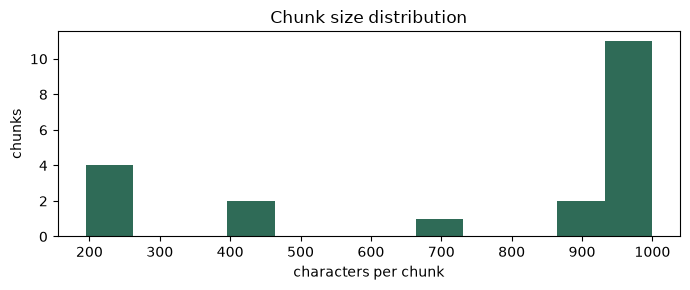

In [148]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(chunk_df["chars"], bins=12, color="#2F6B57")
ax.set_xlabel("characters per chunk"); ax.set_ylabel("chunks"); ax.set_title("Chunk size distribution")
plt.tight_layout(); plt.show()

## 5. Step 3 — Embeddings + FAISS vector store

Chunks are embedded (HuggingFace `all-MiniLM-L6-v2`, 384-d, local CPU) and stored in **FAISS**. The index is cached on disk, keyed by file hashes + chunk settings + embedding model, so re-processing the same papers is instant.

### 5.1 FAISS vector store — autonomous_research_agent.py Section 7: FAISS vector store

In [149]:
# ============================================================================
# SECTION 7: FAISS vector store
# ============================================================================
# FAISS vector store with on-disk caching.
#
# The index is keyed by (file hashes + chunk settings + embedding model), so
# re-uploading the same papers re-uses the saved index instead of re-embedding.

import hashlib
import json
import shutil
from pathlib import Path

from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings


log_vs = get_logger("vectorstore")


def index_key(file_hashes: list[str], chunk_size: int, chunk_overlap: int, emb: Embeddings) -> str:
    raw = json.dumps(
        {"files": sorted(file_hashes), "cs": chunk_size, "co": chunk_overlap, "emb": embedding_name(emb)},
        sort_keys=True,
    )
    return hashlib.sha256(raw.encode()).hexdigest()[:16]


def build_vector_store(chunks: list[Document], emb: Embeddings, key: str | None = None) -> tuple[FAISS, bool]:
    """
    Build (or load from cache) a FAISS index.
    Returns (vector_store, loaded_from_cache).
    """
    if not chunks:
        raise ValueError("No chunks to index — upload at least one readable PDF.")

    path: Path | None = VECTOR_DIR / key if key else None
    if path and (path / "index.faiss").exists():
        try:
            vs = FAISS.load_local(str(path), emb, allow_dangerous_deserialization=True)  # our own files
            log_vs.info("Loaded cached FAISS index %s", key)
            return vs, True
        except Exception as exc:
            log_vs.warning("Cache %s unreadable (%s); rebuilding", key, exc)
            shutil.rmtree(path, ignore_errors=True)

    vs = FAISS.from_documents(chunks, emb)
    if path:
        vs.save_local(str(path))
        log_vs.info("Saved FAISS index %s (%d vectors)", key, len(chunks))
    return vs, False


def clear_cache() -> int:
    """Delete all cached indexes. Returns number removed."""
    n = 0
    for p in VECTOR_DIR.iterdir():
        if p.is_dir():
            shutil.rmtree(p, ignore_errors=True)
            n += 1
    return n

### 5.2 Retriever — autonomous_research_agent.py Section 8: Retriever and citation formatting

In [150]:
# ============================================================================
# SECTION 8: Retriever and citation formatting
# ============================================================================
# Retrieval layer: semantic / MMR search over FAISS, optional per-paper filtering,
# multi-query retrieval, and context formatting with citation tags ([S1], [S2] ...).

from dataclasses import dataclass
from typing import Optional

from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document


log_ret = get_logger("retriever")


@dataclass
class Citation:
    tag: str
    source: str
    page: int
    section: str
    snippet: str

    def label(self) -> str:
        return f"[{self.tag}] {self.source} — p.{self.page} ({self.section})"


class ResearchRetriever:
    """Thin, testable wrapper around a FAISS store."""

    def __init__(self, store: FAISS, top_k: int = 5, search_type: str = "mmr"):
        self.store = store
        self.top_k = top_k
        self.search_type = search_type

    def search(self, query: str, k: Optional[int] = None, source: Optional[str] = None) -> list[Document]:
        k = k or self.top_k
        flt = {"source": source} if source else None
        try:
            if self.search_type == "mmr":
                return self.store.max_marginal_relevance_search(
                    query, k=k, fetch_k=max(20, k * 4), lambda_mult=0.6, filter=flt
                )
            return self.store.similarity_search(query, k=k, filter=flt)
        except Exception as exc:
            log_ret.exception("Search failed for %r: %s", query, exc)
            return []

    def search_with_scores(self, query: str, k: Optional[int] = None) -> list[tuple[Document, float]]:
        """L2 distance scores (lower = closer) — used in evaluation."""
        return self.store.similarity_search_with_score(query, k=k or self.top_k)

    def by_section(self, pattern: str, source: Optional[str] = None, limit: int = 2) -> list[Document]:
        return section_docs(self.store, pattern, source, limit)

    def multi_query(self, queries: list[str], k_each: int = 3, source: Optional[str] = None,
                    limit: Optional[int] = None) -> list[Document]:
        """Run several queries and de-duplicate by chunk id (keeps first-seen order)."""
        seen, out = set(), []
        for q in queries:
            for d in self.search(q, k=k_each, source=source):
                cid = d.metadata.get("chunk_id", id(d))
                if cid not in seen:
                    seen.add(cid)
                    out.append(d)
        return out[:limit] if limit else out


def _section_match(md: dict, pattern: str, source: Optional[str]) -> bool:
    import re
    text = str(md.get("sections") or md.get("section", ""))
    return bool(re.search(pattern, text, re.I)) and (not source or md.get("source") == source)


def section_docs(store: FAISS, pattern: str, source: Optional[str] = None, limit: int = 2) -> list[Document]:
    """
    Section-aware retrieval: return chunks whose detected section heading matches
    `pattern` (regex), e.g. "limitation" or "result|experiment". Complements the
    semantic search when the user asks about a specific part of a paper.
    """
    import re
    docs = [d for d in store.docstore._dict.values() if _section_match(d.metadata, pattern, source)]
    # chunks that *start* in the section first, then chunks that merely contain its heading
    docs.sort(key=lambda d: 0 if re.search(pattern, str(d.metadata.get("section", "")), re.I) else 1)
    return docs[:limit]


def format_context(docs: list[Document], max_chars_each: int = 1400) -> tuple[str, list[Citation]]:
    """
    Turn retrieved chunks into an LLM context block where every chunk is
    prefixed with a citation tag, plus the matching Citation objects.
    """
    parts, cites = [], []
    for i, d in enumerate(docs, start=1):
        tag = f"S{i}"
        md = d.metadata
        cite = Citation(
            tag=tag,
            source=md.get("source", "unknown"),
            page=int(md.get("page", 0)),
            section=md.get("sections") or md.get("section", "-"),
            snippet=truncate(d.page_content.replace("\n", " "), 220),
        )
        cites.append(cite)
        parts.append(f"[{tag}] ({cite.source}, p.{cite.page}, {cite.section})\n{truncate(d.page_content, max_chars_each)}")
    return "\n\n".join(parts), cites

### 5.3 Demo — build the index and test semantic search

In [151]:
key = index_key([p.file_hash for p in papers], cfg.chunk_size, cfg.chunk_overlap, emb)
t0 = time.perf_counter()
store, cached = build_vector_store(chunks, emb, key)
print(f"FAISS index: {store.index.ntotal} vectors, dim={store.index.d}, cached={cached}, {time.perf_counter()-t0:.2f}s")

retriever = ResearchRetriever(store, top_k=cfg.top_k, search_type=cfg.search_type)
for d, score in retriever.search_with_scores("What are the limitations of the approach?", k=3):
    print(f"L2={score:.3f} | {d.metadata['source'][:28]} p.{d.metadata['page']} [{d.metadata['sections']}]\n   {d.page_content[:150]!r}")

FAISS index: 20 vectors, dim=2048, cached=True, 0.00s
L2=1.797 | hirag_sum_long_document_summ p.3 [Conclusion And Future Work, References]
   'through multimodal encoders, and evaluate the approach with domain experts in medicine and\neconomics.\nReferences\n[1] This synthetic paper has no real '
L2=1.863 | hirag_sum_long_document_summ p.1 [Abstract, Introduction]
   'claims by 37% while using 62% fewer input tokens than full-context prompting.\n1 Introduction\nResearchers face a rapidly growing volume of publications'
L2=1.868 | hirag_sum_long_document_summ p.2 [Results, Limitations]
   'ROUGE-L\nUnsupported claims\nInput tokens\nTruncation (4k)\n38.2\n11.0\n26.8\n13.9%\n4,000\nMap-reduce\n40.5\n12.6\n29.1\n12.8%\n11,500\nFull context\n42.0\n13.8\n30.9\n'


## 6. Step 4 — The agents, one at a time

### 6.1 Research Agent
Plans **aspect queries** (problem, method, data, results, limitations, future work); with a real LLM it also generates extra paper-specific queries from the abstract (query expansion). It combines **section-aware anchors** with **MMR semantic search** and returns a context block where every chunk is tagged `[S#]`.

**Shared LLM helper** — autonomous_research_agent.py Section 9: Agent base helper

In [152]:
# ============================================================================
# SECTION 9: Agent base helper
# ============================================================================
# Shared plumbing for all agents: a single `call_llm` helper built on LCEL
# (prompt | llm | StrOutputParser) with retries and error handling.

import time

from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate


log_agents = get_logger("agents")

BASE_SYSTEM = (
    "You are a meticulous AI research assistant that reads scientific papers. "
    "Use ONLY the information inside <context>. Every bullet must end with the "
    "citation tag(s) of the chunk(s) it came from, e.g. [S2] or [S1][S4]. "
    "If the context does not contain the answer, say so plainly. Never invent "
    "numbers, datasets, or claims."
)


def call_llm(llm: BaseChatModel, system: str, human: str, retries: int = 2, **variables) -> str:
    """
    Run a prompt through the LLM. `human` may contain {placeholders} filled from
    `variables`. Retries transient failures with exponential back-off.
    """
    prompt = ChatPromptTemplate.from_messages([("system", system), ("human", human)])
    chain = prompt | llm | StrOutputParser()
    last_exc: Exception | None = None
    for attempt in range(retries + 1):
        try:
            return chain.invoke(variables).strip()
        except Exception as exc:  # network / rate limit / provider errors
            last_exc = exc
            if is_permanent_error(exc):  # wrong model or key: retrying cannot help
                raise RuntimeError(friendly_llm_error(exc)) from exc
            wait = 2 ** attempt
            log_agents.warning("LLM call failed (attempt %d/%d): %s — retrying in %ss",
                        attempt + 1, retries + 1, exc, wait)
            time.sleep(wait)
    raise RuntimeError(friendly_llm_error(last_exc, attempts=retries + 1)) from last_exc


def is_permanent_error(exc: Exception) -> bool:
    text = str(exc).lower()
    return any(k in text for k in ("model_not_found", "does not exist", "invalid_api_key", "incorrect api key",
                                   "api key not valid", "error code: 401", "error code: 403", "error code: 404",
                                   "permission_denied", "not found for api version"))


def friendly_llm_error(exc: Exception, attempts: int = 1) -> str:
    """Turn provider errors into a message that says what to do next."""
    text = str(exc)
    low = text.lower()
    if "model_not_found" in low or "does not exist" in low or "not found for api version" in low or "error code: 404" in low:
        return ("The selected model is not available for your API key. Choose another model in the sidebar — "
                f"the list shows the models your key can use. (Provider said: {text[:200]})")
    if any(k in low for k in ("invalid_api_key", "incorrect api key", "api key not valid", "error code: 401")):
        return "The API key was rejected. Check that it is correct and belongs to the provider selected in the sidebar."
    if "error code: 403" in low or "permission_denied" in low:
        return f"Your API key is not allowed to use this model or service. (Provider said: {text[:200]})"
    if "connection" in low or "timed out" in low or "timeout" in low:
        return ("Couldn't connect to the AI provider. Check the internet connection and try again; "
                "if it keeps failing, the provider may be down.")
    if "429" in low or "rate limit" in low or "quota" in low:
        return "The provider's rate limit or quota was reached. Wait a minute, choose a smaller model, or check your plan."
    return f"LLM call failed after {attempts} attempt(s): {text[:300]}"


def headings_block(sections: list[str]) -> str:
    """Markdown heading template the LLM must follow."""
    return "\n".join(f"## {s}" for s in sections)

**Research Agent code** — autonomous_research_agent.py Section 10: Research Agent

In [153]:
# ============================================================================
# SECTION 10: Research Agent
# ============================================================================
# Research Agent
# --------------
# Plans what to look for in a paper and gathers evidence from the vector store.
#
# * Starts from a set of aspect queries (problem, method, data, results ...)
# * In LLM mode it also *autonomously* expands the plan with extra, paper-specific
#   search queries generated from the abstract (query expansion).
# * Returns a citation-tagged context block ready for the downstream agents.

from dataclasses import dataclass, field

from langchain_core.language_models.chat_models import BaseChatModel


log_research = get_logger("research_agent")

ASPECT_QUERIES: list[str] = [
    "research problem, motivation and objective of the paper",
    "proposed method, model architecture and approach",
    "datasets, benchmarks and experimental setup",
    "main results, performance metrics and comparison with baselines",
    "limitations, weaknesses and failure cases",
    "conclusion and future work",
]

# Paper sections that most likely hold each aspect (section-aware retrieval)
ASPECT_SECTIONS: list[str] = [
    "introduction",
    "method|approach|model|architecture",
    "experiment|setup|evaluation",
    "result|ablation",
    "limitation",
    "conclusion|future",
]


@dataclass
class ResearchBundle:
    paper: str
    queries: list[str]
    context: str
    citations: list[Citation] = field(default_factory=list)
    n_chunks: int = 0


class ResearchAgent:
    def __init__(self, llm: BaseChatModel, retriever: ResearchRetriever):
        self.llm = llm
        self.retriever = retriever

    def plan_queries(self, paper: PaperDocument, n_extra: int = 3) -> list[str]:
        """Aspect queries + (LLM mode) paper-specific queries derived from the abstract."""
        queries = list(ASPECT_QUERIES)
        if is_offline(self.llm) or not paper.abstract:
            return queries
        try:
            raw = call_llm(
                self.llm,
                "You plan literature searches. Output only a bullet list.",
                "Given this abstract, write {n} short, specific search queries that would "
                "retrieve the most important technical details of the paper.\n\nAbstract:\n{abstract}",
                n=n_extra,
                abstract=paper.abstract[:2000],
            )
            extra = [q.strip('"') for q in bullets_to_list(raw)][:n_extra]
            log_research.info("Query expansion added: %s", extra)
            return queries + extra
        except Exception as exc:
            log_research.warning("Query expansion skipped: %s", exc)
            return queries

    def gather(self, paper: PaperDocument, k_each: int = 2, max_chunks: int = 12) -> ResearchBundle:
        """Retrieve evidence for one paper (filtered to that paper's chunks)."""
        queries = self.plan_queries(paper)
        # 1) section-aware anchors: one chunk from each canonical section, if detected
        anchors = []
        for pattern in ASPECT_SECTIONS:
            anchors += self.retriever.by_section(pattern, source=paper.file_name, limit=1)
        # 2) semantic multi-query retrieval (MMR) for everything else
        semantic = self.retriever.multi_query(queries, k_each=k_each, source=paper.file_name)
        seen, docs = set(), []
        for d in anchors + semantic:
            cid = d.metadata.get("chunk_id")
            if cid not in seen:
                seen.add(cid)
                docs.append(d)
        docs = docs[:max_chunks]
        # Always include the opening of the paper (abstract) as anchor evidence.
        context, cites = format_context(docs)
        if paper.abstract:
            context = f"[S0] ({paper.file_name}, p.1, Abstract)\n{paper.abstract}\n\n" + context
            cites.insert(0, Citation("S0", paper.file_name, 1, "Abstract", paper.abstract[:220]))
        return ResearchBundle(paper.file_name, queries, context, cites, len(docs))

*Demo:*

In [154]:
research = ResearchAgent(llm, retriever)
paper = papers[1]                      # HiRAG-Sum paper
bundle = research.gather(paper)
print("Queries:", *bundle.queries, sep="\n  - ")
print(f"\nRetrieved {bundle.n_chunks} chunks; citations:")
for c in bundle.citations: print("  ", c.label())

Queries:
  - research problem, motivation and objective of the paper
  - proposed method, model architecture and approach
  - datasets, benchmarks and experimental setup
  - main results, performance metrics and comparison with baselines
  - limitations, weaknesses and failure cases
  - conclusion and future work

Retrieved 9 chunks; citations:
   [S0] hirag_sum_long_document_summarization.pdf — p.1 (Abstract)
   [S1] hirag_sum_long_document_summarization.pdf — p.1 (Introduction, Related Work)
   [S2] hirag_sum_long_document_summarization.pdf — p.2 (Method)
   [S3] hirag_sum_long_document_summarization.pdf — p.2 (Experimental Setup, Results)
   [S4] hirag_sum_long_document_summarization.pdf — p.2 (Results, Limitations)
   [S5] hirag_sum_long_document_summarization.pdf — p.3 (Limitations, Conclusion And Future Work, References)
   [S6] hirag_sum_long_document_summarization.pdf — p.3 (Conclusion And Future Work, References)
   [S7] hirag_sum_long_document_summarization.pdf — p.1 (Related

### 6.2 Summarizer Agent
Fills a fixed template — **TL;DR, Problem Statement, Methodology, Datasets and Experiments, Key Findings, Limitations, Future Work, Keywords** — and must cite every bullet.

**Summarizer Agent code** — autonomous_research_agent.py Section 11: Summarizer Agent

In [155]:
# ============================================================================
# SECTION 11: Summarizer Agent
# ============================================================================
# Summarizer Agent
# ----------------
# Produces a structured, citation-grounded summary of a research paper.
# Accepts reviewer feedback so the orchestrator can ask it to revise (reflection loop).

from dataclasses import dataclass, field

from langchain_core.language_models.chat_models import BaseChatModel


SUMMARY_SECTIONS = [
    "TL;DR",
    "Problem Statement",
    "Methodology",
    "Datasets and Experiments",
    "Key Findings",
    "Limitations",
    "Future Work",
    "Keywords",
]

STYLE_GUIDE = {
    "Concise": "Keep each section to 1-3 tight bullets.",
    "Detailed": "Use 3-6 bullets per section with concrete numbers where available.",
    "Beginner-friendly": "Explain jargon in plain English, as for a first-year student; 2-4 bullets per section.",
}

PROMPT = """Summarise the research paper "{title}" using the evidence below.
{style}
Respond in markdown using EXACTLY these headings, in this order:
{headings}
TL;DR must be one or two sentences. Keywords is a comma-separated list.
{feedback}
<context>
{context}
</context>"""


@dataclass
class PaperSummary:
    paper: str
    title: str
    sections: dict[str, str]
    raw: str
    revision: int = 0
    feedback_history: list[str] = field(default_factory=list)

    def as_text(self) -> str:
        return "\n\n".join(f"{k}\n{v}" for k, v in self.sections.items() if v)


class SummarizerAgent:
    def __init__(self, llm: BaseChatModel):
        self.llm = llm

    def summarize(self, bundle: ResearchBundle, title: str, style: str = "Detailed",
                  feedback: str = "", revision: int = 0) -> PaperSummary:
        fb = f"\nA reviewer flagged problems with your previous draft — fix them:\n{feedback}\n" if feedback else ""
        raw = call_llm(
            self.llm,
            BASE_SYSTEM,
            PROMPT,
            title=title,
            style=STYLE_GUIDE.get(style, STYLE_GUIDE["Detailed"]),
            headings=headings_block(SUMMARY_SECTIONS),
            feedback=fb,
            context=bundle.context,
        )
        return PaperSummary(
            paper=bundle.paper,
            title=title,
            sections=parse_sections(raw, SUMMARY_SECTIONS),
            raw=raw,
            revision=revision,
        )

*Demo:*

In [156]:
from IPython.display import Markdown, display
summarizer = SummarizerAgent(llm)
summary = summarizer.summarize(bundle, paper.title, style="Detailed")
display(Markdown(summary.raw))

## TL;DR
- We propose HiRAG-Sum, a hierarchical retrieval-augmented summarization framework that splits a paper into section-aware chunks, retrieves evidence for each summary aspect, and composes a structured summary with explicit source citations. [S0]
- On a benchmark of 1,200 computer-science papers, HiRAG-Sum improves ROUGE-L by 4.8 points over a truncation baseline and reduces unsupported claims by 37% while using 62% fewer input tokens than full-context prompting. [S0]

## Problem Statement
- Large language models produce fluent summaries of short texts, but they struggle with long scientific papers that exceed their context window and mix many sections of uneven importance. [S0]
- First, we introduce an aspect-driven retrieval strategy that gathers evidence separately for the problem, method, data, results and limitations of a paper. [S1]
- The central problem is that a typical research paper contains eight to fifteen thousand tokens, while the most informative statements are scattered across the abstract, method, results and limitations sections. [S8]

## Methodology
- In the generation stage, the retrieved chunks are tagged with identifiers such as S1 and S2, and the language model is instructed to fill fixed headings: TL;DR, problem statement, methodology, datasets, key findings, limitations and future work. [S2]
- HiRAG-Sum consists of four stages: section-aware chunking, aspect retrieval, structured generation and reflective review. [S7]
- In the review stage, a deterministic reviewer computes coverage as the share of filled headings, grounding as the share of bullets carrying a valid tag, and faithfulness as the share of numbers that also appear in the evidence. [S9]

## Datasets and Experiments
- We report ROUGE-1, ROUGE-2 and ROUGE-L against the reference abstract, the unsupported-claim rate judged by two annotators, and the number of input tokens consumed per paper. [S3]
- We collected a dataset of 1,200 open-access computer-science papers with author-written abstracts, using 1,000 papers for prompt development and 200 papers for testing. [S9]
- We compare against three baselines: a truncation baseline that feeds the first 4,000 tokens to the model, a map-reduce baseline that summarizes every chunk and then merges the partial summaries, and a full-context baseline that uses a long-context model with the entire paper. [S9]

## Key Findings
- HiRAG-Sum achieves the best ROUGE-L score of 31.6, compared with 26.8 for the truncation baseline and 29.1 for map-reduce. [S3]
- The reviewer loop reduces the unsupported-claim rate from 11.4% to 7.2%, a relative reduction of 37%. [S3]
- Revisions were triggered for 18% of papers, mostly because the limitations section was empty in the first draft. [S3]

## Limitations
- Section detection relies on heading patterns and fails on papers with unconventional layouts or scanned pages. [S5]
- The reviewer checks numeric faithfulness but cannot detect subtle misinterpretations of qualitative claims. [S5]
- Finally, the benchmark covers only computer-science papers, so performance on biomedical or social-science literature is unknown. [S5]

## Future Work
- We presented HiRAG-Sum, a hierarchical retrieval-augmented framework that produces structured, cited summaries of long scientific papers. [S5]
- Aspect retrieval and a reflective reviewer together improve summary quality while reducing cost. [S5]
- In future work we plan to extend the reviewer with an entailment model, support figures and tables through multimodal encoders, and evaluate the approach with domain experts in medicine and economics. [S5]

## Keywords
papers, reviewer, hirag-sum, computer-science papers, truncation baseline, input tokens, aspect retrieval, summaries, summary, aspect, baseline, input

### 7.3 Reviewer Agent (self-reflection)
Scores the draft on **coverage** (sections filled), **grounding** (bullets with valid `[S#]` citations) and **faithfulness** (every number appears in the evidence). Below 0.7 — or any hallucinated number — the orchestrator sends the feedback back to the Summarizer.

**Reviewer Agent code** — autonomous_research_agent.py Section 12: Reviewer Agent (self-reflection)

In [157]:
# ============================================================================
# SECTION 12: Reviewer Agent (self-reflection)
# ============================================================================
# Reviewer Agent (self-reflection)
# --------------------------------
# Quality-gates the summary before it reaches the user:
#
# * Coverage   – are all required sections filled?
# * Grounding  – what share of bullets carry a valid [S#] citation?
# * Faithfulness – are the numbers quoted in the summary present in the source?
#
# If the score is below threshold, it returns actionable feedback and the
# orchestrator loops back to the Summarizer (bounded by MAX_REFLECTION_LOOPS).

import re
from dataclasses import dataclass, field


@dataclass
class Review:
    coverage: float
    grounding: float
    faithfulness: float
    score: float
    passed: bool
    issues: list[str] = field(default_factory=list)

    def feedback(self) -> str:
        return "\n".join(f"- {i}" for i in self.issues)


_NUM = re.compile(r"\b\d+(?:\.\d+)?%?")


class ReviewerAgent:
    def __init__(self, threshold: float = 0.7):
        self.threshold = threshold

    def review(self, summary: PaperSummary, bundle: ResearchBundle) -> Review:
        issues: list[str] = []
        valid_tags = {c.tag for c in bundle.citations}

        # 1) coverage
        required = [s for s in SUMMARY_SECTIONS if s != "Keywords"]
        missing = [s for s in required if not summary.sections.get(s, "").strip()]
        coverage = 1 - len(missing) / len(required)
        if missing:
            issues.append(f"Missing or empty sections: {', '.join(missing)}.")

        # 2) grounding — bullets with at least one valid citation tag
        bullets = [
            ln for s, body in summary.sections.items() if s not in ("Keywords", "TL;DR")
            for ln in body.splitlines() if ln.strip().startswith(("-", "*", "•"))
        ]
        cited = [b for b in bullets if any(t in valid_tags for t in re.findall(r"\[(S\d+)\]", b))]
        grounding = len(cited) / len(bullets) if bullets else 0.0
        if grounding < 0.8:
            issues.append(
                f"Only {len(cited)}/{len(bullets)} bullets cite a source; add [S#] tags to every bullet."
            )
        bad_tags = set(re.findall(r"\[(S\d+)\]", summary.raw)) - valid_tags
        if bad_tags:
            issues.append(f"Citation tags not in the context: {', '.join(sorted(bad_tags))}.")

        # 3) faithfulness — every number in the summary should appear in the evidence
        nums = set(_NUM.findall(re.sub(r"\[S\d+\]", "", summary.as_text()).replace(",", "")))
        evidence = bundle.context.replace(",", "")
        unsupported = [n for n in nums if n not in evidence]
        faithfulness = 1 - len(unsupported) / len(nums) if nums else 1.0
        if unsupported:
            issues.append(f"Numbers not found in the source (possible hallucination): {', '.join(sorted(unsupported)[:8])}.")

        score = round(0.4 * coverage + 0.35 * grounding + 0.25 * faithfulness, 3)
        # any number missing from the evidence is a hard fail, even if the weighted score is fine
        passed = score >= self.threshold and not unsupported
        return Review(round(coverage, 3), round(grounding, 3), round(faithfulness, 3), score, passed, issues)

*Demo:*

In [158]:
reviewer = ReviewerAgent(threshold=0.7)
review = reviewer.review(summary, bundle)
print(review)

Review(coverage=1.0, grounding=1.0, faithfulness=1.0, score=1.0, passed=True, issues=[])


### 7.4 Critical Analyst Agent — strengths, weaknesses, novelty, tone, key terms

**Analyst Agent code** — autonomous_research_agent.py Section 13: Critical Analyst Agent

In [159]:
# ============================================================================
# SECTION 13: Critical Analyst Agent
# ============================================================================
# Critical Analyst Agent
# ----------------------
# Goes beyond summarising: evaluates contributions, strengths, weaknesses,
# novelty and practical applications, runs tone/sentiment analysis on the
# paper's claims, extracts key terms and — when several papers are loaded —
# compares them side by side.

from dataclasses import dataclass, field

from langchain_core.language_models.chat_models import BaseChatModel


ANALYSIS_SECTIONS = [
    "Key Contributions",
    "Strengths",
    "Weaknesses",
    "Novelty",
    "Practical Applications",
    "Open Questions",
]

COMPARISON_SECTIONS = [
    "Common Themes",
    "Key Differences",
    "Methodology Comparison",
    "Results Comparison",
    "Recommended Reading Order",
]

ANALYSIS_PROMPT = """Act as an expert peer reviewer for the paper "{title}".
Critically evaluate it using the evidence below. Be specific and fair.
Respond in markdown using EXACTLY these headings:
{headings}
<context>
{context}
</context>"""

COMPARE_PROMPT = """Compare the following research papers using their summaries.
Respond in markdown using EXACTLY these headings:
{headings}
Refer to papers by their short names.
<context>
{context}
</context>"""


@dataclass
class PaperAnalysis:
    paper: str
    sections: dict[str, str]
    tone: dict
    keywords: list[tuple[str, int]]
    stats: dict = field(default_factory=dict)


class AnalystAgent:
    def __init__(self, llm: BaseChatModel):
        self.llm = llm

    def analyze(self, paper: PaperDocument, bundle: ResearchBundle) -> PaperAnalysis:
        raw = call_llm(
            self.llm, BASE_SYSTEM, ANALYSIS_PROMPT,
            title=paper.title, headings=headings_block(ANALYSIS_SECTIONS), context=bundle.context,
        )
        return PaperAnalysis(
            paper=paper.file_name,
            sections=parse_sections(raw, ANALYSIS_SECTIONS),
            tone=analyze_tone(paper.full_text),
            keywords=top_keywords(paper.full_text, 15),
            stats={
                "pages": paper.num_pages,
                "words": paper.num_words,
                "sections_detected": len(paper.sections),
                "est_reading_time_min": round(paper.num_words / 230),
            },
        )

    def compare(self, summaries: list[PaperSummary]) -> dict[str, str]:
        """Cross-paper comparison (multi-document RAG)."""
        if len(summaries) < 2:
            return {}
        blocks = []
        for i, s in enumerate(summaries, start=1):
            body = "\n".join(
                plain_text(v) for k, v in s.sections.items()
                if k in ("TL;DR", "Problem Statement", "Methodology", "Key Findings", "Limitations")
            )
            blocks.append(f"[S{i}] ({s.paper}, {s.title}, summary)\n{body}")
        raw = call_llm(
            self.llm, BASE_SYSTEM, COMPARE_PROMPT,
            headings=headings_block(COMPARISON_SECTIONS), context="\n\n".join(blocks),
        )
        return parse_sections(raw, COMPARISON_SECTIONS)

*Demo:*

In [160]:
analyst = AnalystAgent(llm)
analysis = analyst.analyze(paper, bundle)
display(Markdown("\n\n".join(f"**{k}**\n{v}" for k, v in analysis.sections.items())))
print("Tone:", analysis.tone)
print("Key terms:", [k for k, _ in analysis.keywords[:10]])

**Key Contributions**
- Large language models produce fluent summaries of short texts, but they struggle with long scientific papers that exceed their context window and mix many sections of uneven importance. [S0]
- We propose HiRAG-Sum, a hierarchical retrieval-augmented summarization framework that splits a paper into section-aware chunks, retrieves evidence for each summary aspect, and composes a structured summary with explicit source citations. [S0]
- Third, we add a reviewer loop that scores coverage, grounding and numeric faithfulness and requests a revision when the score falls below a threshold. [S1]

**Strengths**
- On a benchmark of 1,200 computer-science papers, HiRAG-Sum improves ROUGE-L by 4.8 points over a truncation baseline and reduces unsupported claims by 37% while using 62% fewer input tokens than full-context prompting. [S0]
- HiRAG-Sum achieves the best ROUGE-L score of 31.6, compared with 26.8 for the truncation baseline and 29.1 for map-reduce. [S3]
- The reviewer loop reduces the unsupported-claim rate from 11.4% to 7.2%, a relative reduction of 37%. [S3]

**Weaknesses**
- Section detection relies on heading patterns and fails on papers with unconventional layouts or scanned pages. [S5]
- The reviewer checks numeric faithfulness but cannot detect subtle misinterpretations of qualitative claims. [S5]
- Finally, the benchmark covers only computer-science papers, so performance on biomedical or social-science literature is unknown. [S5]

**Novelty**
- Unlike prior retrieval-augmented approaches that issue a single query, HiRAG-Sum issues one query per summary aspect and keeps provenance for every retrieved chunk. [S7]
- The central problem is that a typical research paper contains eight to fifteen thousand tokens, while the most informative statements are scattered across the abstract, method, results and limitations sections. [S8]
- Truncating the input discards late sections such as results and limitations, and naive chunk-by-chunk summarization loses the global structure of the argument. [S8]

**Practical Applications**
- First, we introduce an aspect-driven retrieval strategy that gathers evidence separately for the problem, method, data, results and limitations of a paper. [S1]
- Second, we design a citation-preserving prompt format that forces every generated statement to reference its supporting chunk. [S1]
- Researchers face a rapidly growing volume of publications, and reading every relevant paper in full is no longer practical. [S8]

**Open Questions**
- We presented HiRAG-Sum, a hierarchical retrieval-augmented framework that produces structured, cited summaries of long scientific papers. [S5]
- Aspect retrieval and a reflective reviewer together improve summary quality while reducing cost. [S5]
- In future work we plan to extend the reviewer with an entailment model, support figures and tables through multimodal encoders, and evaluate the approach with domain experts in medicine and economics. [S5]

Tone: {'polarity': -0.111, 'positive_terms': 8, 'negative_terms': 10, 'hedging_per_100_words': 0.31, 'claim_style': 'Assertive', 'label': 'Balanced / neutral'}
Key terms: ['papers', 'hirag-sum', 'reviewer', 'input tokens', 'input', 'tokens', 'limitations', 'hirag-sum hierarchical', 'hierarchical retrieval-augmented', 'long scientific']


## 7. Step 5 — Autonomous orchestration with LangGraph

The `ResearchOrchestrator` wires the agents into a `StateGraph`. The conditional edge after `review` is what makes the system *autonomous*: the agent decides by itself whether its summary is good enough or must be revised.

**Report Writer Agent code** — autonomous_research_agent.py Section 14: Report Writer Agent

In [161]:
# ============================================================================
# SECTION 14: Report Writer Agent
# ============================================================================
# Report Writer Agent
# -------------------
# Turns the outputs of the other agents into a final research brief:
# executive summary, recommendations and conclusion, plus a structured
# `ResearchReport` object consumed by the PDF / DOCX / Markdown exporters.

from dataclasses import dataclass, field
from datetime import datetime

from langchain_core.language_models.chat_models import BaseChatModel


REPORT_SECTIONS = ["Executive Summary", "Recommendations", "Conclusion"]

REPORT_PROMPT = """Write the closing sections of a research brief about the paper(s) below,
for a busy reader who must decide whether to adopt or build on this work.
Respond in markdown using EXACTLY these headings:
{headings}
Executive Summary: 3-5 bullets. Recommendations: 3-5 actionable bullets
(who should read it, how to apply it, what to verify). Conclusion: 2-3 bullets.
<context>
{context}
</context>"""


@dataclass
class ResearchReport:
    title: str
    generated_at: str
    llm_label: str
    papers: list[dict]                       # [{file, title, pages, words}]
    summaries: list[PaperSummary]
    analyses: list[PaperAnalysis]
    reviews: dict[str, Review]
    comparison: dict[str, str]
    closing: dict[str, str]                  # Executive Summary / Recommendations / Conclusion
    citations: dict[str, list[Citation]] = field(default_factory=dict)


class ReportAgent:
    def __init__(self, llm: BaseChatModel):
        self.llm = llm

    def write_closing(self, summaries: list[PaperSummary], analyses: list[PaperAnalysis]) -> dict[str, str]:
        blocks = []
        for i, s in enumerate(summaries, start=1):
            a = next((x for x in analyses if x.paper == s.paper), None)
            parts = [plain_text(v) for k, v in s.sections.items() if k != "Keywords" and v]
            if a:
                parts += [plain_text(v) for v in a.sections.values() if v]
            blocks.append(f"[S{i}] ({s.paper}, {s.title}, summary)\n" + "\n".join(parts))
        raw = call_llm(
            self.llm, BASE_SYSTEM, REPORT_PROMPT,
            headings=headings_block(REPORT_SECTIONS), context="\n\n".join(blocks),
        )
        return parse_sections(raw, REPORT_SECTIONS)

    def build(self, papers, summaries, analyses, reviews, comparison, closing, citations, llm_label) -> ResearchReport:
        title = summaries[0].title if len(summaries) == 1 else f"Literature Brief: {len(summaries)} Papers"
        return ResearchReport(
            title=title,
            generated_at=datetime.now().strftime("%Y-%m-%d %H:%M"),
            llm_label=llm_label,
            papers=[
                {"file": p.file_name, "title": p.title, "pages": p.num_pages, "words": p.num_words}
                for p in papers
            ],
            summaries=summaries,
            analyses=analyses,
            reviews=reviews,
            comparison=comparison,
            closing=closing,
            citations=citations,
        )

**Orchestrator code** — autonomous_research_agent.py Section 15: Orchestrator (LangGraph workflow)

In [162]:
# ============================================================================
# SECTION 15: Orchestrator (LangGraph workflow)
# ============================================================================
# Orchestrator — the autonomous multi-agent workflow, built with LangGraph.
#
#     START
#       │
#       ▼
#     plan ──► research ──► summarize ──► review ──┐
#                               ▲                  │ score < threshold
#                               └──── revise ◄─────┤ and loops left
#                                                  │ otherwise
#                                                  ▼
#                                    analyze ──► compare ──► report ──► END
#
# * plan      : decides the work (papers, style, whether comparison is needed)
# * research  : Research Agent gathers citation-tagged evidence per paper
# * summarize : Summarizer Agent drafts structured summaries
# * review    : Reviewer Agent scores coverage / grounding / faithfulness
#               and routes back for a revision when quality is too low
# * analyze   : Critical Analyst Agent (strengths, weaknesses, tone, keywords)
# * compare   : cross-paper comparison (only when >1 paper)
# * report    : Report Writer Agent (executive summary, recommendations, conclusion)

import operator
import time
from typing import Annotated, Callable, Optional, TypedDict

from langchain_core.language_models.chat_models import BaseChatModel
from langgraph.graph import END, START, StateGraph


log_orch = get_logger("orchestrator")


class AgentState(TypedDict, total=False):
    style: str
    plan: list[str]
    bundles: dict[str, ResearchBundle]
    summaries: dict[str, PaperSummary]
    reviews: dict[str, Review]
    revision: int
    analyses: dict[str, PaperAnalysis]
    comparison: dict[str, str]
    report: ResearchReport
    trace: Annotated[list[dict], operator.add]   # append-only execution log


class ResearchOrchestrator:
    def __init__(self, llm: BaseChatModel, retriever: ResearchRetriever, papers: list[PaperDocument],
                 llm_label: str = "", max_reflection_loops: int = 1, review_threshold: float = 0.7):
        self.papers = {p.file_name: p for p in papers}
        self.llm_label = llm_label
        self.max_loops = max_reflection_loops
        self.research = ResearchAgent(llm, retriever)
        self.summarizer = SummarizerAgent(llm)
        self.reviewer = ReviewerAgent(review_threshold)
        self.analyst = AnalystAgent(llm)
        self.writer = ReportAgent(llm)
        self.graph = self._build_graph()

    # ------------------------------------------------------------------ nodes
    @staticmethod
    def _trace(step: str, agent: str, detail: str, start: float) -> dict:
        return {"step": step, "agent": agent, "detail": detail, "seconds": round(time.perf_counter() - start, 2)}

    def _plan(self, state: AgentState) -> AgentState:
        t = time.perf_counter()
        plan = ["research", "summarize", "review", "analyze"]
        if len(self.papers) > 1:
            plan.append("compare")
        plan.append("report")
        detail = f"{len(self.papers)} paper(s); style={state.get('style', 'Detailed')}; steps={' → '.join(plan)}"
        return {"plan": plan, "revision": 0, "trace": [self._trace("plan", "Planner", detail, t)]}

    def _research(self, state: AgentState) -> AgentState:
        t = time.perf_counter()
        bundles = {name: self.research.gather(p) for name, p in self.papers.items()}
        n = sum(b.n_chunks for b in bundles.values())
        q = len(next(iter(bundles.values())).queries)
        return {"bundles": bundles,
                "trace": [self._trace("research", "Research Agent", f"{q} queries/paper, {n} chunks retrieved", t)]}

    def _summarize(self, state: AgentState) -> AgentState:
        t = time.perf_counter()
        summaries = dict(state.get("summaries", {}))
        reviews = state.get("reviews", {})
        revision = state.get("revision", 0)
        todo = [n for n in self.papers if n not in summaries or not reviews.get(n, Review(0, 0, 0, 0, True)).passed]
        for name in todo:
            fb = reviews[name].feedback() if name in reviews else ""
            summaries[name] = self.summarizer.summarize(
                state["bundles"][name], self.papers[name].title, state.get("style", "Detailed"), fb, revision
            )
        label = "revision" if revision else "draft"
        return {"summaries": summaries,
                "trace": [self._trace("summarize", "Summarizer Agent", f"{label} for {len(todo)} paper(s)", t)]}

    def _review(self, state: AgentState) -> AgentState:
        t = time.perf_counter()
        reviews = {n: self.reviewer.review(state["summaries"][n], state["bundles"][n]) for n in self.papers}
        detail = "; ".join(f"{n[:25]}: score {r.score} ({'pass' if r.passed else 'revise'})" for n, r in reviews.items())
        return {"reviews": reviews, "trace": [self._trace("review", "Reviewer Agent", detail, t)]}

    def _route_after_review(self, state: AgentState) -> str:
        failed = [n for n, r in state["reviews"].items() if not r.passed]
        if failed and state.get("revision", 0) < self.max_loops:
            return "revise"
        return "accept"

    def _bump_revision(self, state: AgentState) -> AgentState:
        return {"revision": state.get("revision", 0) + 1,
                "trace": [{"step": "reflect", "agent": "Reviewer Agent",
                           "detail": "quality below threshold → sending feedback to Summarizer", "seconds": 0.0}]}

    def _analyze(self, state: AgentState) -> AgentState:
        t = time.perf_counter()
        analyses = {n: self.analyst.analyze(p, state["bundles"][n]) for n, p in self.papers.items()}
        return {"analyses": analyses,
                "trace": [self._trace("analyze", "Analyst Agent", "contributions, strengths, weaknesses, tone, keywords", t)]}

    def _compare(self, state: AgentState) -> AgentState:
        t = time.perf_counter()
        if len(self.papers) < 2:
            return {"comparison": {}, "trace": [self._trace("compare", "Analyst Agent", "skipped (single paper)", t)]}
        comp = self.analyst.compare(list(state["summaries"].values()))
        return {"comparison": comp, "trace": [self._trace("compare", "Analyst Agent", f"compared {len(self.papers)} papers", t)]}

    def _report(self, state: AgentState) -> AgentState:
        t = time.perf_counter()
        summaries = [state["summaries"][n] for n in self.papers]
        analyses = [state["analyses"][n] for n in self.papers]
        closing = self.writer.write_closing(summaries, analyses)
        report = self.writer.build(
            list(self.papers.values()), summaries, analyses, state["reviews"], state.get("comparison", {}),
            closing, {n: b.citations for n, b in state["bundles"].items()}, self.llm_label,
        )
        return {"report": report, "trace": [self._trace("report", "Report Writer Agent", "executive summary, recommendations, conclusion", t)]}

    # ------------------------------------------------------------------ graph
    def _build_graph(self):
        g = StateGraph(AgentState)
        g.add_node("plan", self._plan)
        g.add_node("research", self._research)
        g.add_node("summarize", self._summarize)
        g.add_node("review", self._review)
        g.add_node("reflect", self._bump_revision)
        g.add_node("analyze", self._analyze)
        g.add_node("compare", self._compare)
        g.add_node("report", self._report)

        g.add_edge(START, "plan")
        g.add_edge("plan", "research")
        g.add_edge("research", "summarize")
        g.add_edge("summarize", "review")
        g.add_conditional_edges("review", self._route_after_review, {"revise": "reflect", "accept": "analyze"})
        g.add_edge("reflect", "summarize")
        g.add_edge("analyze", "compare")
        g.add_edge("compare", "report")
        g.add_edge("report", END)
        return g.compile()

    def run(self, style: str = "Detailed", on_step: Optional[Callable[[dict], None]] = None) -> AgentState:
        """Execute the workflow; `on_step` receives each trace entry as it happens (for UI progress)."""
        final: AgentState = {"trace": []}
        for update in self.graph.stream({"style": style, "trace": []}, stream_mode="updates"):
            for _node, delta in update.items():
                if not delta:
                    continue
                for entry in delta.get("trace", []):
                    log_orch.info("[%s] %s — %s (%.2fs)", entry["step"], entry["agent"], entry["detail"], entry["seconds"])
                    if on_step:
                        on_step(entry)
                for k, v in delta.items():
                    final[k] = final.get("trace", []) + v if k == "trace" else v
        return final

    def mermaid(self) -> str:
        """Mermaid source of the compiled graph (for docs / README)."""
        return self.graph.get_graph().draw_mermaid()

*Demo:*

In [163]:
orch = ResearchOrchestrator(llm, retriever, papers, llm_label=cfg.llm_provider, max_reflection_loops=1)
print(orch.mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	plan(plan)
	research(research)
	summarize(summarize)
	review(review)
	reflect(reflect)
	analyze(analyze)
	compare(compare)
	report(report)
	__end__([<p>__end__</p>]):::last
	__start__ --> plan;
	analyze --> compare;
	compare --> report;
	plan --> research;
	reflect --> summarize;
	research --> summarize;
	review -. &nbsp;accept&nbsp; .-> analyze;
	review -. &nbsp;revise&nbsp; .-> reflect;
	summarize --> review;
	report --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [164]:
t0 = time.perf_counter()
state = orch.run(style="Detailed")
total_time = time.perf_counter() - t0
trace_df = pd.DataFrame(state["trace"])
print(f"Workflow finished in {total_time:.2f}s")
trace_df

Workflow finished in 0.06s


,step,agent,detail,seconds
0,plan,Planner,3 paper(s); style=Detailed; steps=research → summarize → review → analyze → compare → report,0.00
1,research,Research Agent,"6 queries/paper, 19 chunks retrieved",0.03
2,summarize,Summarizer Agent,draft for 3 paper(s),0.01
3,review,Reviewer Agent,agentic_peer_review_multi: score 1.0 (pass); hirag_sum_long_document_s: score 1.0 (pass); 07_pdf_crop_disease_detec:...,0.00
4,analyze,Analyst Agent,"contributions, strengths, weaknesses, tone, keywords",0.01
5,compare,Analyst Agent,compared 3 papers,0.00
6,report,Report Writer Agent,"executive summary, recommendations, conclusion",0.00


In [165]:
report = state["report"]
for s in report.summaries:
    display(Markdown(f"### {s.title}\n" + "\n\n".join(f"**{k}**\n{v}" for k, v in s.sections.items() if k in ("TL;DR", "Key Findings", "Limitations"))))

### Agentic Peer Review: Multi-Agent Critique for Scientific Document Understanding
**TL;DR**
- We introduce Agentic Peer Review (APR), a multi-agent system in which a reader agent extracts claims, a methodologist agent inspects experimental design, a skeptic agent searches for weaknesses, and a chair agent writes a balanced verdict. [S0]
- Agents communicate through a shared workspace and a planner decides which agent acts next. [S0]

**Key Findings**
- On 300 conference submissions with public reviews, APR identifies 68% of the weaknesses raised by human reviewers, compared with 41% for a single-prompt baseline, while costing under 0.05 USD per paper. [S0]
- APR achieves a weakness recall of 68% compared with 41% for the single-prompt baseline, with precision improving from 63% to 74%. [S3]
- Adaptive planning reduced cost by 22% relative to running every agent a fixed number of times, and the average cost was 0.047 USD per paper. [S4]

**Limitations**
- APR cannot verify results that require running code or accessing private data, and it inherits biases present in the human reviews used for evaluation. [S4]
- Agents occasionally repeat each other's points, which inflates review length. [S4]
- Future work will add code execution for reproducibility checks, calibrate the recommendation score against acceptance decisions, and study how authors respond to automated feedback. [S4]

### HiRAG-Sum: Hierarchical Retrieval-Augmented Summarization of Long Scientific Papers
**TL;DR**
- We propose HiRAG-Sum, a hierarchical retrieval-augmented summarization framework that splits a paper into section-aware chunks, retrieves evidence for each summary aspect, and composes a structured summary with explicit source citations. [S0]
- On a benchmark of 1,200 computer-science papers, HiRAG-Sum improves ROUGE-L by 4.8 points over a truncation baseline and reduces unsupported claims by 37% while using 62% fewer input tokens than full-context prompting. [S0]

**Key Findings**
- HiRAG-Sum achieves the best ROUGE-L score of 31.6, compared with 26.8 for the truncation baseline and 29.1 for map-reduce. [S3]
- The reviewer loop reduces the unsupported-claim rate from 11.4% to 7.2%, a relative reduction of 37%. [S3]
- Revisions were triggered for 18% of papers, mostly because the limitations section was empty in the first draft. [S3]

**Limitations**
- Section detection relies on heading patterns and fails on papers with unconventional layouts or scanned pages. [S5]
- The reviewer checks numeric faithfulness but cannot detect subtle misinterpretations of qualitative claims. [S5]
- Finally, the benchmark covers only computer-science papers, so performance on biomedical or social-science literature is unknown. [S5]

### LeafScan: Early Crop Disease Detection from Smartphone Photos
**TL;DR**
- We present LeafScan, a compact image classifier that runs offline on low-cost smartphones and recognises 14 diseases of tomato, potato and maize leaves. [S0]
- The app asks the user to photograph one leaf, checks image sharpness, and shows the top diagnosis with a confidence level and treatment advice written with local agronomists. [S1]

**Key Findings**
- Trained on 61,000 field photos, LeafScan reaches 93.2% accuracy on field images from new farms and runs in 0.4 seconds on a phone, helping farmers act about six days earlier in a pilot with 320 farmers. [S0]
- On unseen farms LeafScan reached 93.2% accuracy, compared with 71.5% for the laboratory-trained model and 95.0% for the teacher model, which is twenty times larger and needs a server. [S2]
- In the pilot, farmers using the app treated crops 6.1 days earlier on average, and estimated yield losses fell from 18% to 11%. [S2]

**Limitations**
- Smallholder farmers often notice crop disease only when it has already spread. [S0]
- Accuracy dropped to 81% for early-stage symptoms that are barely visible. [S3]
- The model covers only three crops, and the pilot's yield estimates were reported by farmers rather than measured. [S3]

In [166]:
display(Markdown("### Cross-paper comparison\n" + "\n\n".join(f"**{k}**\n{v}" for k, v in report.comparison.items())))
display(Markdown("### Executive summary\n" + report.closing["Executive Summary"]))

### Cross-paper comparison
**Common Themes**
- We introduce Agentic Peer Review (APR), a multi-agent system in which a reader agent extracts claims, a methodologist agent inspects experimental design, a skeptic agent searches for weaknesses, and a chair agent writes a balanced verdict. [S1]
- We propose HiRAG-Sum, a hierarchical retrieval-augmented summarization framework that splits a paper into section-aware chunks, retrieves evidence for each summary aspect, and composes a structured summary with explicit source citations. [S2]
- First, we introduce an aspect-driven retrieval strategy that gathers evidence separately for the problem, method, data, results and limitations of a paper. [S2]

**Key Differences**
- On a benchmark of 1,200 computer-science papers, HiRAG-Sum improves ROUGE-L by 4.8 points over a truncation baseline and reduces unsupported claims by 37% while using 62% fewer input tokens than full-context prompting. [S2]
- Baselines were a model trained on laboratory photos and the large teacher model. [S3]
- On unseen farms LeafScan reached 93.2% accuracy, compared with 71.5% for the laboratory-trained model and 95.0% for the teacher model, which is twenty times larger and needs a server. [S3]

**Methodology Comparison**
- APR uses four specialised agents and a planner. [S1]
- The planner inspects the workspace after every step and decides whether another agent should act, allowing extra skeptic rounds for papers with many claims. [S1]
- HiRAG-Sum consists of four stages: section-aware chunking, aspect retrieval, structured generation and reflective review. [S2]

**Results Comparison**
- APR achieves a weakness recall of 68% compared with 41% for the single-prompt baseline, with precision improving from 63% to 74%. [S1]
- HiRAG-Sum achieves the best ROUGE-L score of 31.6, compared with 26.8 for the truncation baseline and 29.1 for map-reduce. [S2]
- Trained on 61,000 field photos, LeafScan reaches 93.2% accuracy on field images from new farms and runs in 0.4 seconds on a phone, helping farmers act about six days earlier in a pilot with 320 farmers. [S3]

**Recommended Reading Order**
- Agents communicate through a shared workspace and a planner decides which agent acts next. [S1]
- Adaptive planning reduced cost by 22% relative to running every agent a fixed number of times, and the average cost was 0.047 USD per paper. [S1]
- In the generation stage, the retrieved chunks are tagged with identifiers such as S1 and S2, and the language model is instructed to fill fixed headings: TL;DR, problem statement, methodology, datasets, key findings, limitations and future work. [S2]

### Executive summary
- Agentic Peer Review shows that dividing critique among specialised agents yields more complete and more precise assessments than a single prompt, at very low cost. [S1]
- We propose HiRAG-Sum, a hierarchical retrieval-augmented summarization framework that splits a paper into section-aware chunks, retrieves evidence for each summary aspect, and composes a structured summary with explicit source citations. [S2]
- First, we introduce an aspect-driven retrieval strategy that gathers evidence separately for the problem, method, data, results and limitations of a paper. [S2]

## 8. Step 6 — Conversational Q&A with memory

The Q&A agent **routes** each question (intent + which paper it refers to — by file name, title or acronym), **condenses** follow-ups using chat history (LLM mode), retrieves (section-aware + MMR) and answers with citations.

It can also **create** material from a paper — interview or exam questions with model answers, quizzes, simple explanations, drafts. For these it gathers evidence from every section (front matter, problem, method, data, results, limitations, future work) and may write new text, but every fact must still come from the paper with a citation. Offline mode uses fixed question templates; an LLM writes tailored questions.

**Q&A Agent code** — autonomous_research_agent.py Section 16: Q&A Agent (conversational RAG)

In [167]:
# ============================================================================
# SECTION 16: Q&A Agent (conversational RAG)
# ============================================================================
# Q&A (Chat) Agent
# ----------------
# Conversational RAG with memory:
#
# 1. Router     – classifies the question intent (summary / method / results / ...
#                 or "create": interview questions, quizzes, simple explanations, drafts)
#                 and detects whether it targets one specific paper.
# 2. Condenser  – rewrites follow-ups ("what about its limitations?") into a
#                 standalone query using the chat history (LLM mode).
# 3. Retriever  – searches FAISS (filtered to a paper if one was named).
# 4. Answerer   – grounded answer with [S#] citations. For "create" requests it may
#                 write new material (questions, explanations) but every fact about
#                 the paper must still come from the paper and be cited.

import re
from dataclasses import dataclass, field

from langchain_core.language_models.chat_models import BaseChatModel

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

log_qa = get_logger("qa_agent")

INTENTS: dict[str, list[str]] = {
    # requests to *produce* something from the paper (checked first: wins ties)
    "create": ["interview", "viva", "quiz", "exam question", "mcq", "q&a", "questions and answers",
               "question and answer", "questions should i ask", "questions to ask", "questions can i ask",
               "practice question", "flashcard", "mock", "explain like", "eli5", "simple terms", "layman",
               "write a", "write an", "draft", "make a", "prepare me", "help me prepare", "outline",
               "slides", "presentation", "email", "linkedin", "tweet", "blog", "cheat sheet"],
    "authors": ["who wrote", "who created", "author", "written by", "who are the researchers", "who did this",
                "who made", "who conducted", "researchers behind"],
    "comparison": ["compare", "difference", "versus", " vs", "better than", "contrast", "both papers", "each paper"],
    "summary": ["summar", "overview", "tl;dr", "about", "gist", "explain the paper"],
    "methodology": ["method", "approach", "architecture", "how does", "how do", "algorithm", "pipeline", "model"],
    "results": ["result", "performance", "accuracy", "score", "outperform", "benchmark", "metric", "how well",
                "find", "found", "outcome"],
    "limitations": ["limitation", "weakness", "drawback", "fail", "risk", "problem with"],
    "future_work": ["future", "next step", "extend", "open question"],
    "data": ["dataset", "data", "corpus", "benchmark"],
}

INTENT_QUERY_HINT = {
    "summary": "main contribution, problem and results",
    "methodology": "proposed method architecture approach",
    "results": "experimental results metrics compared to baselines",
    "limitations": "limitations weaknesses failure cases",
    "future_work": "future work conclusion",
    "comparison": "method and results",
    "data": "datasets experimental setup",
}

# Chat answers may *compose* (explain, rephrase, write questions) but facts must be grounded.
CHAT_SYSTEM = (
    "You are a helpful AI research assistant. The user is working with the research paper(s) in "
    "<context>. Every fact you state about the paper (names, numbers, data, methods, results, claims) "
    "must come from <context> and end with its citation tag, e.g. [S2]. You MAY compose new material "
    "from those facts — explanations, interview or exam questions with answers, outlines, drafts — and "
    "that is never a reason to refuse. If something the user asks for is not in the context, say which "
    "part is missing and still answer the rest. Never invent numbers, datasets, people or claims."
)

ANSWER_PROMPT = """Conversation so far:
{history}

Answer the user's question using only the context. Be precise and concise;
use bullets for lists and cite every claim with [S#] tags.
<question>{question}</question>
<context>
{context}
</context>"""

INTENT_SECTIONS = {
    "methodology": "method|approach|architecture|model",
    "results": "result|ablation|evaluation",
    "limitations": "limitation",
    "future_work": "future|conclusion",
    "data": "experiment|setup|data",
    "summary": "abstract|introduction|conclusion",
}

CREATE_PROMPT = """Conversation so far:
{history}

The user wants you to create something from the paper(s):
<question>{question}</question>

Create it from the context below.
- For interview, viva, exam or quiz requests: write 6-8 numbered questions in bold that together cover the
  problem, the method, the data and experiments, the results, the limitations and future work. Under each,
  give a short model answer (1-3 sentences) built from the context, with [S#] tags. If the user is the
  interviewer, phrase the questions to the author ("Why did you...?") and label the answers "Expected answer".
- If the request is about who wrote the research, use only names that appear in the context; if none
  appear, say the authors are not listed in the uploaded text.
- For any other request (explanation, outline, email, slides...), follow it, keeping every fact cited.
<context>
{context}
</context>"""

# Offline mode cannot write freely, so "create" requests get question templates whose
# model answers are extracted from the matching section of the paper.
CREATE_TEMPLATES: list[tuple[str, str]] = [
    ("What problem does this research address, and why does it matter?", "abstract|introduction"),
    ("Can you explain the proposed method in simple terms?", "method|approach|architecture|model"),
    ("Which dataset and experiments were used to test it?", "experiment|setup|evaluation"),
    ("What were the main results?", "result|ablation"),
    ("What are the main limitations of this work?", "limitation"),
    ("What future work is suggested?", "conclusion|future"),
]

CONDENSE_PROMPT = """Rewrite the follow-up question as a standalone search query, resolving
pronouns using the chat history. Output only the rewritten question.

History:
{history}

Follow-up: {question}"""


@dataclass
class ChatAnswer:
    question: str
    standalone_question: str
    intent: str
    answer: str
    citations: list[Citation] = field(default_factory=list)
    target_paper: str | None = None


class QAAgent:
    def __init__(self, llm: BaseChatModel, retriever: ResearchRetriever, memory_turns: int = 6):
        self.llm = llm
        self.retriever = retriever
        self.memory_turns = memory_turns
        self.history: list[tuple[str, str]] = []  # (role, text)

    # ---- routing -----------------------------------------------------------
    @staticmethod
    def classify_intent(question: str) -> str:
        q = question.lower()
        scores = {k: sum(c in q for c in cues) for k, cues in INTENTS.items()}
        best = max(scores, key=scores.get)
        return best if scores[best] > 0 else "general"

    @staticmethod
    def paper_aliases(paper) -> list[str]:
        """Ways a user may refer to a paper: file stem, title, title prefix, acronym."""
        aliases = [re.sub(r"\.[a-z0-9]+$", "", paper.file_name.lower()), paper.title.lower()]
        prefix = paper.title.split(":")[0].strip().lower()
        if 1 <= len(prefix.split()) <= 4:
            aliases.append(prefix)
        aliases += [a.lower() for a in re.findall(r"\(([A-Z][A-Za-z\-]{1,10})\)", paper.abstract)]
        return [a for a in aliases if len(a) >= 3]

    # words too common in research titles to identify one paper on their own
    _GENERIC_TITLE_WORDS = set(ENGLISH_STOP_WORDS) | {
        "paper", "papers", "study", "research", "results", "result", "model", "models", "using", "based",
        "analysis", "approach", "method", "methods", "document", "file", "detection", "learning", "system",
        "systems", "report", "data", "field", "towards", "toward", "excel", "word", "powerpoint", "csv", "text",
        "markdown", "pdf",
    }

    @classmethod
    def _title_words(cls, text: str) -> set[str]:
        return {w for w in re.findall(r"[a-z0-9]+", text.lower()) if len(w) >= 4 and w not in cls._GENERIC_TITLE_WORDS}

    @classmethod
    def detect_paper(cls, question: str, papers: list) -> str | None:
        """
        Which paper the question is about: first by name/title/acronym, then by distinctive
        title words ("the hybrid work study", "the help-desk chatbot pilot").
        """
        q = question.lower()
        for p in papers:
            if any(re.search(rf"(?<![a-z]){re.escape(a)}(?![a-z])", q) for a in cls.paper_aliases(p)):
                return p.file_name
        q_words = cls._title_words(question)
        if not q_words or len(papers) < 2:
            return None
        vocab = {p.file_name: cls._title_words(p.title + " " + re.sub(r"[_\-.]", " ", p.file_name)) for p in papers}
        scores = []
        for name, words in vocab.items():
            hits = q_words & words
            # a single long word counts if no other paper's title uses it (e.g. "chatbot")
            unique = [w for w in hits if len(w) >= 6 and all(w not in v for n, v in vocab.items() if n != name)]
            scores.append((len(hits) + (1 if unique else 0), name))
        scores.sort(reverse=True)
        best, runner_up = scores[0], (scores[1] if len(scores) > 1 else (0, None))
        return best[1] if best[0] >= 2 and best[0] > runner_up[0] else None

    def _history_text(self) -> str:
        turns = self.history[-self.memory_turns * 2:]
        return "\n".join(f"{r.upper()}: {' '.join(t[:500].split())}" for r, t in turns) or "(no previous messages)"

    def condense(self, question: str) -> str:
        if not self.history or is_offline(self.llm):
            return question
        try:
            return call_llm(self.llm, "You rewrite questions.", CONDENSE_PROMPT,
                            history=self._history_text(), question=question).strip() or question
        except Exception as exc:
            log_qa.warning("Condense failed: %s", exc)
            return question

    # ---- main entry -----------------------------------------------------------
    def ask(self, question: str, papers: list) -> ChatAnswer:
        """`papers` are the loaded PaperDocument objects (used for routing)."""
        paper_names = [p.file_name for p in papers]
        intent = self.classify_intent(question)
        target = self.detect_paper(question, papers)
        standalone = self.condense(question)
        query = f"{standalone} {INTENT_QUERY_HINT.get(intent, '')}".strip()

        if intent == "authors":
            answer, cites = self._authors(standalone, papers, target)
            self.history += [("user", question), ("assistant", answer)]
            return ChatAnswer(question, standalone, intent, answer, cites, target)

        if intent == "create":
            answer, cites = self._create(standalone, papers, target)
            self.history += [("user", question), ("assistant", answer)]
            log_qa.info("Create request (%s, paper=%s) answered with %d sources", question[:60], target, len(cites))
            return ChatAnswer(question, standalone, intent, answer, cites, target)

        if intent == "comparison" and len(paper_names) > 1 and not target:
            # retrieve evenly from every paper so the comparison is balanced
            docs = []
            for name in paper_names:
                docs += self.retriever.search(query, k=max(2, self.retriever.top_k // len(paper_names) + 1), source=name)
        else:
            docs = self.retriever.search(query, source=target)
            pattern = INTENT_SECTIONS.get(intent)
            if pattern:  # put chunks from the matching paper section first
                boost = self.retriever.by_section(pattern, source=target, limit=2)
                ids = {d.metadata.get("chunk_id") for d in boost}
                docs = boost + [d for d in docs if d.metadata.get("chunk_id") not in ids]
                docs = docs[: self.retriever.top_k + 1]

        if not docs:
            answer = "I could not find relevant passages in the uploaded papers for that question."
            cites: list[Citation] = []
        else:
            context, cites = format_context(docs)
            answer = call_llm(self.llm, CHAT_SYSTEM, ANSWER_PROMPT, history=self._history_text(),
                              question=standalone, context=context)

        self.history += [("user", question), ("assistant", answer)]
        log_qa.info("Q(%s, intent=%s, paper=%s) answered with %d sources", question[:60], intent, target, len(cites))
        return ChatAnswer(question, standalone, intent, answer, cites, target)

    # ---- "who wrote it" -----------------------------------------------------------
    def _authors(self, question: str, papers: list, target: str | None) -> tuple[str, list[Citation]]:
        """Authors come from each paper's front matter (title page)."""
        chosen = [p for p in papers if p.file_name == target] if target else papers
        docs = [d for p in chosen for d in self.retriever.by_section("front matter", source=p.file_name, limit=1)]
        context, cites = format_context(docs)
        if docs and not is_offline(self.llm):
            return call_llm(self.llm, CHAT_SYSTEM, ANSWER_PROMPT, history=self._history_text(),
                            question=question, context=context), cites
        tag = {c.source: c.tag for c in cites}
        lines = []
        for p in chosen:
            who = p.authors or "the authors are not listed in the uploaded text"
            ref = f" [{tag[p.file_name]}]" if p.file_name in tag and p.authors else ""
            lines.append(f"- **{p.title.split(':')[0]}**: {who}{ref}")
        return "\n".join(lines), cites

    # ---- "create" requests ------------------------------------------------------
    def _paper_overview_docs(self, source: str, per_paper: int) -> list:
        """Front matter (title, authors) + abstract + one chunk from every main section of a paper."""
        docs, seen = [], set()
        for pattern in ["front matter|abstract"] + ASPECT_SECTIONS:
            for d in self.retriever.by_section(pattern, source=source, limit=1):
                if d.metadata.get("chunk_id") not in seen:
                    seen.add(d.metadata.get("chunk_id"))
                    docs.append(d)
        return docs[:per_paper]

    def _create(self, question: str, papers: list, target: str | None) -> tuple[str, list[Citation]]:
        chosen = [p for p in papers if p.file_name == target] if target else papers
        per_paper = 7 if len(chosen) <= 2 else 4
        docs = [d for p in chosen for d in self._paper_overview_docs(p.file_name, per_paper)]
        if not docs:
            docs = self.retriever.search(question, source=target)
        if not docs:
            return "I could not find text in the uploaded papers to build that from.", []
        context, cites = format_context(docs)
        if not is_offline(self.llm):
            return call_llm(self.llm, CHAT_SYSTEM, CREATE_PROMPT, history=self._history_text(),
                            question=question, context=context), cites
        return self._create_offline(chosen, context, cites), cites

    def _create_offline(self, chosen: list, context: str, cites: list[Citation]) -> str:
        """Template questions + model answers extracted from the matching section (no LLM needed)."""
        blocks = re.split(r"\n\n(?=\[S\d+\] \()", context)
        out = ["Questions and model answers drawn from the paper "
               "(offline mode uses fixed question templates; choose an LLM for tailored questions):"]
        used: set[str] = set()  # don't repeat the same sentence under two questions
        for paper in chosen:
            mine = [b for b, c in zip(blocks, cites) if c.source == paper.file_name]
            if len(chosen) > 1:
                out.append(f"\n### {paper.title.split(':')[0]}")
            for i, (q, pattern) in enumerate(CREATE_TEMPLATES, start=1):
                relevant = [b for b, c in zip(blocks, cites)
                            if c.source == paper.file_name and re.search(pattern, c.section, re.I)] or mine
                raw = call_llm(self.llm, CHAT_SYSTEM, ANSWER_PROMPT, history="(none)", question=q,
                               context="\n\n".join(relevant))
                bullets = [ln for ln in raw.splitlines() if ln.strip().startswith("-") and ln not in used][:2]
                used.update(bullets)
                out.append(f"\n**Q{i}. {q}**\n" + "\n".join(bullets or ["- Not found in the uploaded text."]))
        return "\n".join(out)

    def reset(self) -> None:
        self.history.clear()

*Demo:*

In [168]:
qa = QAAgent(llm, retriever, memory_turns=6)
for q in ["What are the limitations of HiRAG-Sum?",
          "How does the APR method work?",
          "Compare the results of both papers",
          "Give me interview questions and answers about HiRAG-Sum"]:
    a = qa.ask(q, papers)
    display(Markdown(f"**Q: {q}**  \n*intent = {a.intent}, paper = {a.target_paper}*\n\n{a.answer}\n\n"
                     + "Sources: " + "; ".join(c.label() for c in a.citations[:4])))
print("Messages in memory:", len(qa.history))

**Q: What are the limitations of HiRAG-Sum?**  
*intent = limitations, paper = hirag_sum_long_document_summarization.pdf*

- Section detection relies on heading patterns and fails on papers with unconventional layouts or scanned pages. [S1]
- The reviewer checks numeric faithfulness but cannot detect subtle misinterpretations of qualitative claims. [S1]
- Finally, the benchmark covers only computer-science papers, so performance on biomedical or social-science literature is unknown. [S1]
- We presented HiRAG-Sum, a hierarchical retrieval-augmented framework that produces structured, cited summaries of long scientific papers. [S1]

Sources: [S1] hirag_sum_long_document_summarization.pdf — p.3 (Limitations, Conclusion And Future Work, References); [S2] hirag_sum_long_document_summarization.pdf — p.2 (Results, Limitations); [S3] hirag_sum_long_document_summarization.pdf — p.1 (Related Work, Method); [S4] hirag_sum_long_document_summarization.pdf — p.3 (Conclusion And Future Work, References)

**Q: How does the APR method work?**  
*intent = methodology, paper = agentic_peer_review_multi_agent_critique.pdf*

- The chair agent integrates all notes into a structured review with strengths, weaknesses and a recommendation. [S1]
- The planner inspects the workspace after every step and decides whether another agent should act, allowing extra skeptic rounds for papers with many claims. [S1]
- APR uses four specialised agents and a planner. [S2]
- The reader agent extracts the main claims and evidence. [S2]

Sources: [S1] agentic_peer_review_multi_agent_critique.pdf — p.1 (Method, Experiments, Results); [S2] agentic_peer_review_multi_agent_critique.pdf — p.1 (Introduction, Method); [S3] agentic_peer_review_multi_agent_critique.pdf — p.2 (Results, Limitations And Future Work, Conclusion); [S4] agentic_peer_review_multi_agent_critique.pdf — p.1 (Results)

**Q: Compare the results of both papers**  
*intent = comparison, paper = None*

- The planner inspects the workspace after every step and decides whether another agent should act, allowing extra skeptic rounds for papers with many claims. [S1]
- Adaptive planning reduced cost by 22% relative to running every agent a fixed number of times, and the average cost was 0.047 USD per paper. [S2]
- APR cannot verify results that require running code or accessing private data, and it inherits biases present in the human reviews used for evaluation. [S2]
- Accuracy dropped to 81% for early-stage symptoms that are barely visible. [S6]

Sources: [S1] agentic_peer_review_multi_agent_critique.pdf — p.1 (Method, Experiments, Results); [S2] agentic_peer_review_multi_agent_critique.pdf — p.2 (Results, Limitations And Future Work, Conclusion); [S3] hirag_sum_long_document_summarization.pdf — p.1 (Abstract, Introduction); [S4] hirag_sum_long_document_summarization.pdf — p.1 (Related Work, Method)

**Q: Give me interview questions and answers about HiRAG-Sum**  
*intent = create, paper = hirag_sum_long_document_summarization.pdf*

Questions and model answers drawn from the paper (offline mode uses fixed question templates; choose an LLM for tailored questions):

**Q1. What problem does this research address, and why does it matter?**
- Large language models produce fluent summaries of short texts, but they struggle with long scientific papers that exceed their context window and mix many sections of uneven importance. [S1]
- A lightweight reviewer module checks coverage and grounding and triggers one revision when quality is low. [S1]

**Q2. Can you explain the proposed method in simple terms?**
- In the retrieval stage, chunks are embedded with a 384-dimensional sentence encoder and indexed in a FAISS vector store. [S3]
- For each of six aspects the system issues a query and applies maximal marginal relevance to obtain diverse evidence, keeping at most twelve chunks per paper. [S3]

**Q3. Which dataset and experiments were used to test it?**
- We report ROUGE-1, ROUGE-2 and ROUGE-L against the reference abstract, the unsupported-claim rate judged by two annotators, and the number of input tokens consumed per paper. [S4]
- HiRAG-Sum achieves the best ROUGE-L score of 31.6, compared with 26.8 for the truncation baseline and 29.1 for map-reduce. [S4]

**Q4. What were the main results?**
- The full-context model reaches 30.9 but consumes 2.6 times more input tokens. [S4]
- The reviewer loop reduces the unsupported-claim rate from 11.4% to 7.2%, a relative reduction of 37%. [S4]

**Q5. What are the main limitations of this work?**
- Our evaluation uses author abstracts as references, which reward lexical overlap and may undervalue correct but differently worded summaries. [S6]
- Section detection relies on heading patterns and fails on papers with unconventional layouts or scanned pages. [S6]

**Q6. What future work is suggested?**
- The reviewer checks numeric faithfulness but cannot detect subtle misinterpretations of qualitative claims. [S6]
- We presented HiRAG-Sum, a hierarchical retrieval-augmented framework that produces structured, cited summaries of long scientific papers. [S6]

Sources: [S1] hirag_sum_long_document_summarization.pdf — p.1 (Front Matter, Abstract, Introduction); [S2] hirag_sum_long_document_summarization.pdf — p.1 (Introduction, Related Work); [S3] hirag_sum_long_document_summarization.pdf — p.2 (Method); [S4] hirag_sum_long_document_summarization.pdf — p.2 (Experimental Setup, Results)

Messages in memory: 8


## 09. Testing and evaluation

We evaluate each layer separately:

| Layer | Test | Metric |
|---|---|---|
| Retrieval | 12 labelled questions → expected section | Hit@k, MRR (similarity vs MMR vs section-aware) |
| Summarization | summary vs the author's abstract (abstract hidden from the agent) | ROUGE-1/2/L vs Lead-3 and random baselines |
| Grounding | Reviewer Agent scores | coverage, grounding, faithfulness |
| Safety | summary with injected fake numbers | hallucination detection |
| Routing | 16 labelled questions | intent accuracy, paper detection |
| Robustness | missing / empty files | handled errors |
| File formats | Word, PowerPoint, Markdown, Excel copies of a paper | title & sections detected |
| Performance | per-agent timing | seconds |

### 09.1 Retrieval quality

In [169]:
import re, numpy as np

RETRIEVAL_TESTS = [  # (question, paper, regex of the section that holds the answer)
    ("What problem with long documents does the paper address?", "hirag", "introduction|abstract"),
    ("How are documents chunked and indexed?", "hirag", "method"),
    ("How does the reviewer module decide to revise?", "hirag", "method"),
    ("Which dataset and baselines were used?", "hirag", "experimental setup"),
    ("What ROUGE-L score was achieved?", "hirag", "results"),
    ("What are the weaknesses of the evaluation?", "hirag", "limitations"),
    ("What do the authors plan for future work?", "hirag", "conclusion|future"),
    ("Why is peer review slow and inconsistent?", "agentic", "introduction|abstract"),
    ("What does the skeptic agent do?", "agentic", "method"),
    ("How was weakness recall measured?", "agentic", "experiments"),
    ("How much does the system cost per paper?", "agentic", "results"),
    ("What can the system not verify?", "agentic", "limitations"),
]

def eval_retrieval(mode, k=5, store=store):
    hits, rr = [], []
    for q, ptag, pattern in RETRIEVAL_TESTS:
        src = next(p.file_name for p in papers if p.file_name.startswith(ptag))
        if mode == "section-aware":
            intent = QAAgent.classify_intent(q)
            boost = section_docs(store, INTENT_SECTIONS.get(intent, "^$"), src, 1)
            sem = ResearchRetriever(store, k, "mmr").search(q, k=k, source=src)
            ids = {d.metadata["chunk_id"] for d in boost}
            docs = (boost + [d for d in sem if d.metadata["chunk_id"] not in ids])[:k]
        else:
            docs = ResearchRetriever(store, k, mode).search(q, k=k, source=src)
        ranks = [i for i, d in enumerate(docs, 1) if re.search(pattern, d.metadata["sections"], re.I)]
        hits.append(1 if ranks else 0); rr.append(1 / ranks[0] if ranks else 0)
    return {"mode": mode, f"Hit@{k}": np.mean(hits), "MRR": np.mean(rr)}

# A harder setting too: 400-char chunks -> ~3x more candidates per paper
small_chunks = [c for p in papers for c in chunk_paper(p, 400, 60)]
small_store, _ = build_vector_store(small_chunks, emb, index_key([p.file_hash for p in papers], 400, 60, emb))

rows = []
for label, st_ in [("1000-char chunks", store), ("400-char chunks", small_store)]:
    for m in ["similarity", "mmr", "section-aware"]:
        r1, r3 = eval_retrieval(m, 1, st_), eval_retrieval(m, 3, st_)
        rows.append({"index": label, "mode": m, "Hit@1": r1["Hit@1"], "Hit@3": r3["Hit@3"], "MRR@3": r3["MRR"]})
ret_df = pd.DataFrame(rows)
print(f"{len(chunks)} vs {len(small_chunks)} chunks")
ret_df.round(3)

20 vs 41 chunks


,index,mode,Hit@1,Hit@3,MRR@3
0,1000-char chunks,similarity,0.667,1.000,0.792
1,1000-char chunks,mmr,0.667,1.000,0.792
2,1000-char chunks,section-aware,0.667,1.000,0.806
3,400-char chunks,similarity,0.750,0.917,0.819
4,400-char chunks,mmr,0.750,0.833,0.778
5,400-char chunks,section-aware,0.667,0.833,0.750


### 09.2 Summary quality (ROUGE vs the author's abstract)
To avoid leakage, the agent's evidence excludes the abstract (`S0`) and front-matter chunks. Baselines: **Lead-3** (first three sentences of the introduction) and **Random-3** sentences.

In [170]:
from rouge_score import rouge_scorer
import random

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
random.seed(7)
rows = []
for p in papers:
    # evidence without the abstract / front matter
    docs = [d for d in retriever.multi_query(research.plan_queries(p), k_each=2, source=p.file_name)
            if "Abstract" not in d.metadata["sections"] and "Front Matter" not in d.metadata["sections"]]
    ctx, cites = format_context(docs)
    s = summarizer.summarize(ResearchBundle(p.file_name, [], ctx, cites, len(docs)), p.title, "Concise")
    agent_text = plain_text("\n".join(s.sections[k] for k in ("TL;DR", "Problem Statement", "Methodology", "Key Findings")))

    body = p.full_text.split(p.abstract[-60:])[-1]          # text after the abstract
    sents = split_sentences(body)
    candidates = {"Lead-3": " ".join(sents[:3]), "Random-3": " ".join(random.sample(sents, 3)), "Agent (ours)": agent_text}
    for name, text in candidates.items():
        sc = scorer.score(p.abstract, text)
        rows.append({"paper": p.title.split(":")[0], "system": name,
                     **{m: round(sc[m].fmeasure, 3) for m in ("rouge1", "rouge2", "rougeL")},
                     "words": len(text.split())})
rouge_df = pd.DataFrame(rows)
rouge_df

,paper,system,rouge1,rouge2,rougeL,words
0,Agentic Peer Review,Lead-3,0.237,0.012,0.095,65
1,Agentic Peer Review,Random-3,0.303,0.093,0.184,47
2,Agentic Peer Review,Agent (ours),0.406,0.115,0.242,175
3,HiRAG-Sum,Lead-3,0.211,0.011,0.089,65
4,HiRAG-Sum,Random-3,0.229,0.000,0.091,58
5,HiRAG-Sum,Agent (ours),0.294,0.070,0.128,250
6,LeafScan,Lead-3,0.243,0.029,0.171,65
7,LeafScan,Random-3,0.315,0.069,0.137,70
8,LeafScan,Agent (ours),0.273,0.067,0.133,189


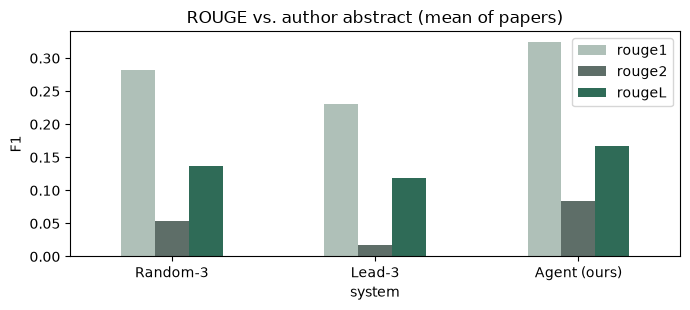

,rouge1,rouge2,rougeL
system,,,
Random-3,0.282,0.054,0.137
Lead-3,0.230,0.017,0.118
Agent (ours),0.324,0.084,0.168


In [171]:
avg = rouge_df.groupby("system")[["rouge1", "rouge2", "rougeL"]].mean().loc[["Random-3", "Lead-3", "Agent (ours)"]]
ax = avg.plot.bar(figsize=(7, 3.2), color=["#AFC0B8", "#5E6E68", "#2F6B57"], rot=0)
ax.set_ylabel("F1"); ax.set_title("ROUGE vs. author abstract (mean of papers)")
plt.tight_layout(); plt.show()
avg.round(3)

### 9.3 Grounding — Reviewer scores from the full workflow

In [172]:
review_df = pd.DataFrame([{"paper": n[:35], "coverage": r.coverage, "grounding": r.grounding,
                           "faithfulness": r.faithfulness, "score": r.score, "passed": r.passed}
                          for n, r in report.reviews.items()])
review_df

,paper,coverage,grounding,faithfulness,score,passed
0,agentic_peer_review_multi_agent_cri,1.0,1.0,1.0,1.0,True
1,hirag_sum_long_document_summarizati,1.0,1.0,1.0,1.0,True
2,07_pdf_crop_disease_detection.pdf,1.0,1.0,1.0,1.0,True


### 9.4 Safety — does the Reviewer catch hallucinated numbers?

In [173]:
import copy
fake = copy.deepcopy(state["summaries"][papers[1].file_name])
fake.sections["Key Findings"] += "\n- The method reaches 97.3% accuracy on ImageNet. [S1]"
fake.raw += "\n- The method reaches 97.3% accuracy on ImageNet. [S1]"
fake_review = reviewer.review(fake, state["bundles"][papers[1].file_name])
print("passed:", fake_review.passed, "| faithfulness:", fake_review.faithfulness)
print("issues:", *fake_review.issues, sep="\n  ")

passed: False | faithfulness: 0.938
issues:
  Numbers not found in the source (possible hallucination): 97.3%.


### 9.5 Routing — intent classification and paper detection

In [174]:
ROUTING_TESTS = [
    ("Summarize the paper", "summary"), ("Give me an overview of the APR paper", "summary"),
    ("How does the model work?", "methodology"), ("Explain the architecture", "methodology"),
    ("What accuracy did they get?", "results"), ("How well does it perform against baselines?", "results"),
    ("What are the drawbacks?", "limitations"), ("Any weaknesses?", "limitations"),
    ("What is the next step for this research?", "future_work"), ("What future work is planned?", "future_work"),
    ("Compare both papers", "comparison"), ("What is the difference between HiRAG-Sum and APR?", "comparison"),
    ("Which dataset was used?", "data"), ("How big is the corpus?", "data"),
    ("Give me interview questions on this paper", "create"), ("Explain the paper in simple terms", "create"),
]
pred = [QAAgent.classify_intent(q) for q, _ in ROUTING_TESTS]
acc = np.mean([p == y for p, (_, y) in zip(pred, ROUTING_TESTS)])
print(f"Intent accuracy: {acc:.0%} ({sum(p == y for p, (_, y) in zip(pred, ROUTING_TESTS))}/{len(ROUTING_TESTS)})")
print(pd.DataFrame({"question": [q for q, _ in ROUTING_TESTS], "expected": [y for _, y in ROUTING_TESTS], "predicted": pred}).to_string(index=False))

print("\nPaper detection:")
for q in ["limitations of HiRAG-Sum", "how does APR plan", "what about agentic peer review", "summarize everything"]:
    print(f"  {q!r:40} -> {QAAgent.detect_paper(q, papers)}")

Intent accuracy: 100% (16/16)
                                         question    expected   predicted
                              Summarize the paper     summary     summary
             Give me an overview of the APR paper     summary     summary
                         How does the model work? methodology methodology
                         Explain the architecture methodology methodology
                      What accuracy did they get?     results     results
      How well does it perform against baselines?     results     results
                          What are the drawbacks? limitations limitations
                                  Any weaknesses? limitations limitations
         What is the next step for this research? future_work future_work
                     What future work is planned? future_work future_work
                              Compare both papers  comparison  comparison
What is the difference between HiRAG-Sum and APR?  comparison  comparison
        

### 9.6 Robustness — error handling

In [175]:
import tempfile
bad = Path(tempfile.mkdtemp()) / "empty.pdf"
from reportlab.pdfgen import canvas
c = canvas.Canvas(str(bad)); c.drawString(100, 750, "x"); c.save()          # nearly-empty PDF

ok_papers, ok_chunks, errors = load_and_chunk([PDFS[0], bad, "does_not_exist.pdf"])
print(f"processed: {len(ok_papers)} paper(s), {len(ok_chunks)} chunks")
print("errors collected (pipeline kept going):", *errors, sep="\n  ")

2026-10-30 00:49:07,470 | ERROR    | research_agent.loader | Failed to process empty.pdf: almost no extractable text (is it a scanned PDF? run OCR first)
2026-10-30 00:49:07,472 | ERROR    | research_agent.loader | Failed to process does_not_exist.pdf: file not found


processed: 1 paper(s), 6 chunks
errors collected (pipeline kept going):
  empty.pdf: almost no extractable text (is it a scanned PDF? run OCR first)
  does_not_exist.pdf: file not found


### 9.7 Other file formats — Word, PowerPoint, Excel, Markdown

The loader also accepts `.docx`, `.pptx`, `.xlsx`, `.csv`, `.txt` and `.md`. To test it, we rebuild the HiRAG-Sum paper as a Word document (real heading styles), a PowerPoint deck (one slide per section, a table and speaker notes) and a Markdown file, plus an Excel workbook of its results. Each one is loaded, and the detected title, sections and size are checked. Old binary formats and unknown types should be rejected with a clear message.

In [176]:
import tempfile
import pandas as pd
from docx import Document as DocxDocument
from pptx import Presentation
from pptx.util import Inches

src = papers[1]                                   # the HiRAG-Sum PDF loaded in step 4
blocks, current = [], None                        # [(heading, [paragraph lines])]
for line in src.full_text.splitlines():
    m = _HEADING.match(line)
    if m:
        current = (m.group(1).strip().title(), []); blocks.append(current)
    elif current and line.strip():
        current[1].append(line.strip())
blocks = [(h, " ".join(lines)) for h, lines in blocks if h != "References"]
fmt_dir = Path(tempfile.mkdtemp())

# Word: headings use Word's own heading styles (no numbers, as Word numbers them itself)
d = DocxDocument(); d.add_heading(src.title, level=0)
for h, body in blocks:
    d.add_heading(h, level=1); d.add_paragraph(body)
d.save(fmt_dir / "hirag_sum.docx")

# PowerPoint: one slide per section, plus a results table with speaker notes
prs = Presentation()
s0 = prs.slides.add_slide(prs.slide_layouts[0]); s0.shapes.title.text = src.title
for h, body in blocks:
    s1 = prs.slides.add_slide(prs.slide_layouts[1]); s1.shapes.title.text = h
    s1.placeholders[1].text_frame.text = body
rows = [["Method", "ROUGE-L", "Unsupported claims"], ["Truncation (4k)", "26.8", "13.9%"],
        ["Map-reduce", "29.1", "12.8%"], ["HiRAG-Sum (ours)", "31.6", "7.2%"]]
s2 = prs.slides.add_slide(prs.slide_layouts[5]); s2.shapes.title.text = "Results table"
tbl = s2.shapes.add_table(4, 3, Inches(0.5), Inches(1.5), Inches(9), Inches(2)).table
for r, row in enumerate(rows):
    for c, v in enumerate(row):
        tbl.cell(r, c).text = v
s2.notes_slide.notes_text_frame.text = "The reviewer loop cut unsupported claims by 37%."
prs.save(fmt_dir / "hirag_sum.pptx")

# Markdown and Excel
(fmt_dir / "hirag_sum.md").write_text(f"# {src.title}\n\n" + "\n\n".join(f"## {h}\n\n{b}" for h, b in blocks))
pd.DataFrame(rows[1:], columns=rows[0]).to_excel(fmt_dir / "hirag_results.xlsx", sheet_name="Main results", index=False)

fmt_rows = []
for f in ["hirag_sum.docx", "hirag_sum.pptx", "hirag_sum.md", "hirag_results.xlsx"]:
    doc = load_document(fmt_dir / f)
    fmt_rows.append({"file": f, "title": doc.title[:45], "pages/parts": doc.num_pages, "words": doc.num_words,
                     "chunks": len(chunk_paper(doc)), "sections found": len(doc.sections)})
fmt_df = pd.DataFrame(fmt_rows)
print(f"PDF original: {len(src.sections)} sections, {src.num_words} words")
display(fmt_df)

# rejected inputs
(fmt_dir / "old.doc").write_bytes(b"x"); (fmt_dir / "notes.zip").write_bytes(b"x")
_, _, fmt_errors = load_and_chunk([fmt_dir / "old.doc", fmt_dir / "notes.zip"])
print("Rejected with a clear message:", *fmt_errors, sep="\n  ")

PDF original: 9 sections, 1016 words


,file,title,pages/parts,words,chunks,sections found
0,hirag_sum.docx,HiRAG-Sum: Hierarchical Retrieval-Augmented S,3,979,9,8
1,hirag_sum.pptx,HiRAG-Sum: Hierarchical Retrieval-Augmented S,10,1014,14,8
2,hirag_sum.md,HiRAG-Sum: Hierarchical Retrieval-Augmented S,3,979,9,8
3,hirag_results.xlsx,Hirag Results,1,41,1,0


2026-10-30 00:49:07,854 | ERROR    | research_agent.loader | Failed to process old.doc: old .doc format — save it as .docx and upload again
2026-10-30 00:49:07,855 | ERROR    | research_agent.loader | Failed to process notes.zip: unsupported file type — use .pdf, .docx, .pptx, .xlsx, .csv, .txt, .md


Rejected with a clear message:
  old.doc: old .doc format — save it as .docx and upload again
  notes.zip: unsupported file type — use .pdf, .docx, .pptx, .xlsx, .csv, .txt, .md


### 9.8 Performance

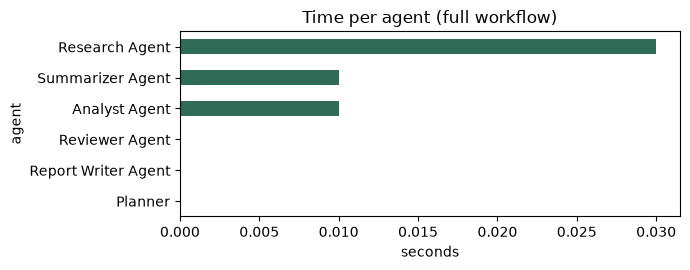

Total: 0.05s for 3 papers


In [177]:
perf = trace_df.groupby("agent")["seconds"].sum().sort_values()
ax = perf.plot.barh(figsize=(7, 2.8), color="#2F6B57"); ax.set_xlabel("seconds"); ax.set_title("Time per agent (full workflow)")
plt.tight_layout(); plt.show()
print(f"Total: {perf.sum():.2f}s for {len(papers)} papers")

## 10. Final results — export the report

### 10.1 Report exporter — autonomous_research_agent.py Section 17: Report export (PDF / DOCX / Markdown)

In [178]:
# ============================================================================
# SECTION 17: Report export (PDF / DOCX / Markdown)
# ============================================================================
# Report export: Markdown, PDF (ReportLab) and DOCX (python-docx).
#
# Report layout
#   1. Title page info (papers, model, quality scores)
#   2. Executive Summary
#   3. Per-paper structured summary  (Research Findings)
#   4. Per-paper critical analysis   (strengths, weaknesses, tone, keywords)
#   5. Cross-paper comparison        (if several papers)
#   6. Recommendations
#   7. Conclusion
#   8. Sources (citation tags -> file / page / section)

import io
import re
from html import escape


# --------------------------------------------------------------------------- #
# Common structure
# --------------------------------------------------------------------------- #


def _blocks(report: ResearchReport) -> list[tuple[str, str, str]]:
    """Flatten the report into (level, heading, body) tuples shared by every exporter."""
    out: list[tuple[str, str, str]] = []
    out.append(("h1", "Executive Summary", report.closing.get("Executive Summary", "")))
    for s in report.summaries:
        out.append(("h1", f"Research Findings — {s.title}", f"Source file: {s.paper}"))
        for name, body in s.sections.items():
            if body:
                out.append(("h2", name, body))
        a = next((x for x in report.analyses if x.paper == s.paper), None)
        if a:
            out.append(("h2", "Critical Analysis", ""))
            for name, body in a.sections.items():
                if body:
                    out.append(("h3", name, body))
            tone = a.tone
            out.append(("h3", "Tone & Sentiment",
                        f"- Overall tone: {tone['label']} (polarity {tone['polarity']})\n"
                        f"- Claim style: {tone['claim_style']} ({tone['hedging_per_100_words']} hedges / 100 words)\n"
                        f"- Positive vs. critical terms: {tone['positive_terms']} / {tone['negative_terms']}"))
            out.append(("h3", "Top Key Terms", ", ".join(k for k, _ in a.keywords)))
        r = report.reviews.get(s.paper)
        if r:
            out.append(("h3", "Quality Check (Reviewer Agent)",
                        f"- Overall score: {r.score} ({'passed' if r.passed else 'below threshold'})\n"
                        f"- Coverage: {r.coverage} | Grounding: {r.grounding} | Faithfulness: {r.faithfulness}"))
    if report.comparison:
        out.append(("h1", "Cross-Paper Comparison", ""))
        for name, body in report.comparison.items():
            if body:
                out.append(("h2", name, body))
    out.append(("h1", "Recommendations", report.closing.get("Recommendations", "")))
    out.append(("h1", "Conclusion", report.closing.get("Conclusion", "")))
    src_lines = []
    for paper, cites in report.citations.items():
        for c in cites:
            src_lines.append(f"- {paper} [{c.tag}]: page {c.page}, section {c.section}")
    out.append(("h1", "Sources", "\n".join(src_lines)))
    return out


def _lines(body: str) -> list[tuple[bool, str]]:
    """Return [(is_bullet, text)]."""
    res = []
    for raw in body.splitlines():
        if not raw.strip():
            continue
        is_bullet = bool(re.match(r"^\s*([-*•]|\d+[.)])\s+", raw))
        res.append((is_bullet, bullets_to_list(raw)[0] if is_bullet else raw.strip()))
    return res


# --------------------------------------------------------------------------- #
# Markdown
# --------------------------------------------------------------------------- #


def to_markdown(report: ResearchReport) -> str:
    md = [f"# {report.title}", "",
          f"*Generated {report.generated_at} by the Autonomous AI Research Agent · Model: {report.llm_label}*", "",
          "| File | Title | Pages | Words |", "|---|---|---|---|"]
    md += [f"| {p['file']} | {p['title']} | {p['pages']} | {p['words']:,} |" for p in report.papers]
    md.append("")
    level = {"h1": "##", "h2": "###", "h3": "####"}
    for lvl, head, body in _blocks(report):
        md += [f"{level[lvl]} {head}", "", body, ""]
    return "\n".join(md)


# --------------------------------------------------------------------------- #
# PDF
# --------------------------------------------------------------------------- #


def to_pdf(report: ResearchReport) -> bytes:
    from reportlab.lib import colors
    from reportlab.lib.enums import TA_LEFT
    from reportlab.lib.pagesizes import A4
    from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
    from reportlab.lib.units import mm
    from reportlab.platypus import (ListFlowable, ListItem, Paragraph, SimpleDocTemplate,
                                    Spacer, Table, TableStyle)

    buf = io.BytesIO()
    doc = SimpleDocTemplate(buf, pagesize=A4, leftMargin=18 * mm, rightMargin=18 * mm,
                            topMargin=18 * mm, bottomMargin=18 * mm, title=report.title,
                            author="Autonomous AI Research Agent")
    ss = getSampleStyleSheet()
    navy = colors.HexColor("#1F3A5F")
    styles = {
        "title": ParagraphStyle("t", parent=ss["Title"], textColor=navy, fontSize=20, leading=24, alignment=TA_LEFT),
        "meta": ParagraphStyle("m", parent=ss["Normal"], textColor=colors.HexColor("#5B6573"), fontSize=9),
        "h1": ParagraphStyle("h1", parent=ss["Heading1"], textColor=navy, fontSize=15, spaceBefore=12, spaceAfter=4),
        "h2": ParagraphStyle("h2", parent=ss["Heading2"], textColor=navy, fontSize=12, spaceBefore=8, spaceAfter=2),
        "h3": ParagraphStyle("h3", parent=ss["Heading3"], fontSize=10.5, spaceBefore=6, spaceAfter=2),
        "body": ParagraphStyle("b", parent=ss["BodyText"], fontSize=9.5, leading=13),
    }

    def p(text: str, style: str) -> Paragraph:
        safe = escape(text)
        safe = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", safe)
        safe = re.sub(r"(\[S\d+\])", r'<font color="#7A8699">\1</font>', safe)
        return Paragraph(safe, styles[style])

    story = [p(report.title, "title"),
             p(f"Generated {report.generated_at} · Autonomous AI Research Agent · Model: {report.llm_label}", "meta"),
             Spacer(1, 6)]
    rows = [["File", "Pages", "Words"]] + [[p(x["file"], "body"), str(x["pages"]), f"{x['words']:,}"] for x in report.papers]
    tbl = Table(rows, colWidths=[110 * mm, 25 * mm, 30 * mm])
    tbl.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), navy), ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTSIZE", (0, 0), (-1, -1), 9), ("GRID", (0, 0), (-1, -1), 0.3, colors.HexColor("#C9D1DB")),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
    ]))
    story += [tbl, Spacer(1, 6)]

    for lvl, head, body in _blocks(report):
        story.append(p(head, lvl))
        items, para = [], []
        for is_bullet, text in _lines(body):
            (items if is_bullet else para).append(text)
        for text in para:
            story.append(p(text, "body"))
        if items:
            story.append(ListFlowable([ListItem(p(t, "body"), leftIndent=10) for t in items],
                                      bulletType="bullet", start="•", leftIndent=10, bulletFontSize=8))

    def footer(canvas, _doc):
        canvas.saveState()
        canvas.setFont("Helvetica", 8)
        canvas.setFillColor(colors.HexColor("#8A94A3"))
        canvas.drawRightString(A4[0] - 18 * mm, 10 * mm, f"Page {_doc.page}")
        canvas.restoreState()

    doc.build(story, onFirstPage=footer, onLaterPages=footer)
    return buf.getvalue()


# --------------------------------------------------------------------------- #
# DOCX
# --------------------------------------------------------------------------- #


def to_docx(report: ResearchReport) -> bytes:
    from docx import Document
    from docx.shared import Pt, RGBColor

    d = Document()
    style = d.styles["Normal"]
    style.font.name = "Calibri"
    style.font.size = Pt(10.5)

    h = d.add_heading(report.title, level=0)
    for run in h.runs:
        run.font.color.rgb = RGBColor(0x1F, 0x3A, 0x5F)
    meta = d.add_paragraph(f"Generated {report.generated_at} · Autonomous AI Research Agent · Model: {report.llm_label}")
    meta.runs[0].font.size = Pt(9)

    t = d.add_table(rows=1, cols=3)
    t.style = "Light Grid Accent 1"
    for cell, txt in zip(t.rows[0].cells, ["File", "Pages", "Words"]):
        cell.text = txt
    for x in report.papers:
        row = t.add_row().cells
        row[0].text, row[1].text, row[2].text = x["file"], str(x["pages"]), f"{x['words']:,}"

    level = {"h1": 1, "h2": 2, "h3": 3}
    for lvl, head, body in _blocks(report):
        d.add_heading(head, level=level[lvl])
        for is_bullet, text in _lines(body):
            d.add_paragraph(text, style="List Bullet" if is_bullet else None)

    buf = io.BytesIO()
    d.save(buf)
    return buf.getvalue()

### 10.2 Pipeline facade — autonomous_research_agent.py Section 18: Pipeline facade

One class used by the Streamlit app: ingest → run agents → chat → export.

In [179]:
# ============================================================================
# SECTION 18: Pipeline facade
# ============================================================================
# ResearchPipeline — one facade used by both the notebook and the Streamlit app.
#
#     pipe = ResearchPipeline(Settings(llm_provider="OpenAI"), api_key="sk-...")
#     pipe.ingest(["paper.pdf"])          # load → chunk → embed → FAISS
#     state = pipe.run_agents("Detailed") # LangGraph multi-agent workflow
#     pipe.ask("What dataset was used?")  # conversational RAG
#     pipe.export(state["report"], "pdf") # PDF / DOCX / Markdown bytes

from dataclasses import dataclass, field
from pathlib import Path
from typing import Callable, Optional


log_pipe = get_logger("pipeline")


@dataclass
class IngestStats:
    files: int = 0
    pages: int = 0
    words: int = 0
    chunks: int = 0
    embedding_model: str = ""
    from_cache: bool = False
    seconds: float = 0.0
    errors: list[str] = field(default_factory=list)


class ResearchPipeline:
    def __init__(self, cfg: Optional[Settings] = None, api_key: Optional[str] = None,
                 embedding_model: Optional[str] = None):
        self.cfg = cfg or Settings()
        self.llm = get_llm(self.cfg, api_key)
        self.embeddings = get_embeddings(embedding_model or self.cfg.embedding_model)
        self.papers: list[PaperDocument] = []
        self.retriever: Optional[ResearchRetriever] = None
        self.qa: Optional[QAAgent] = None
        self.stats = IngestStats()

    @property
    def llm_label(self) -> str:
        if is_offline(self.llm):
            return "Offline extractive model (no API key)"
        return f"{self.cfg.llm_provider} · {self.cfg.resolved_model()}"

    # ------------------------------------------------------------------ ingest
    def ingest(self, paths: list[str | Path]) -> IngestStats:
        with timer() as t:
            papers, chunks, errors = load_and_chunk(paths, self.cfg.chunk_size, self.cfg.chunk_overlap)
            if not papers:
                raise ValueError("None of the files could be processed: " + "; ".join(errors))
            key = index_key([p.file_hash for p in papers], self.cfg.chunk_size, self.cfg.chunk_overlap, self.embeddings)
            store, cached = build_vector_store(chunks, self.embeddings, key)
        self.papers = papers
        self.retriever = ResearchRetriever(store, self.cfg.top_k, self.cfg.search_type)
        self.qa = QAAgent(self.llm, self.retriever, self.cfg.memory_turns)
        self.stats = IngestStats(
            files=len(papers), pages=sum(p.num_pages for p in papers), words=sum(p.num_words for p in papers),
            chunks=len(chunks), embedding_model=embedding_name(self.embeddings), from_cache=cached,
            seconds=t["seconds"], errors=errors,
        )
        log_pipe.info("Ingested %s", self.stats)
        return self.stats

    # ------------------------------------------------------------------ agents
    def _require_ready(self) -> None:
        if not self.retriever:
            raise RuntimeError("Call ingest() with at least one PDF first.")

    def build_orchestrator(self) -> ResearchOrchestrator:
        self._require_ready()
        return ResearchOrchestrator(self.llm, self.retriever, self.papers, self.llm_label,
                                    self.cfg.max_reflection_loops)

    def run_agents(self, style: str = "Detailed", on_step: Optional[Callable[[dict], None]] = None):
        return self.build_orchestrator().run(style=style, on_step=on_step)

    def ask(self, question: str) -> ChatAnswer:
        self._require_ready()
        return self.qa.ask(question, self.papers)

    # ------------------------------------------------------------------ export
    @staticmethod
    def export(report, fmt: str = "pdf") -> bytes:
        fmt = fmt.lower()
        if fmt == "pdf":
            return to_pdf(report)
        if fmt == "docx":
            return to_docx(report)
        if fmt in ("md", "markdown"):
            return to_markdown(report).encode("utf-8")
        raise ValueError(f"Unsupported format: {fmt}")

### 10.3 Demo — export the final report

In [180]:
(OUTPUT_DIR / "research_report.pdf").write_bytes(to_pdf(report))
(OUTPUT_DIR / "research_report.docx").write_bytes(to_docx(report))
(OUTPUT_DIR / "research_report.md").write_text(to_markdown(report), encoding="utf-8")
for f in ("research_report.pdf", "research_report.docx", "research_report.md"):
    print(f"{f:24} {(OUTPUT_DIR / f).stat().st_size/1024:6.1f} KB")

research_report.pdf        25.6 KB
research_report.docx       40.5 KB
research_report.md         26.3 KB


In [181]:
results = {
    "papers": len(papers), "chunks": len(chunks), "embeddings": embedding_name(emb),
    "llm": "offline extractive" if is_offline(llm) else cfg.resolved_model(),
    "retrieval (400-char index)": {r["mode"]: {"Hit@1": round(r["Hit@1"], 3), "Hit@3": round(r["Hit@3"], 3)}
                                   for _, r in ret_df[ret_df["index"] == "400-char chunks"].iterrows()},
    "rougeL_agent": round(float(avg.loc["Agent (ours)", "rougeL"]), 3),
    "rougeL_lead3": round(float(avg.loc["Lead-3", "rougeL"]), 3),
    "mean_reviewer_score": round(float(review_df["score"].mean()), 3),
    "hallucination_caught": not fake_review.passed,
    "intent_accuracy": round(float(acc), 3),
    "workflow_seconds": round(total_time, 2),
}
(OUTPUT_DIR / "evaluation_results.json").write_text(json.dumps(results, indent=2))
pd.Series(results, name="value").to_frame()

,value
papers,3
chunks,20
embeddings,HashingEmbeddings (offline fallback)
llm,offline extractive
retrieval (400-char index),"{'similarity': {'Hit@1': 0.75, 'Hit@3': 0.917}, 'mmr': {'Hit@1': 0.75, 'Hit@3': 0.833}, 'section-aware': {'Hit@1': 0..."
rougeL_agent,0.168
rougeL_lead3,0.118
mean_reviewer_score,1.0
hallucination_caught,True
intent_accuracy,1.0


## 11. Deployment — the Streamlit app

The web interface is **Section 19 of `autonomous_research_agent.py`**. It is not included in this notebook because a Streamlit app only runs with `streamlit run`, not inside Jupyter. It uses the `ResearchPipeline` from Section 18, so everything tested above is exactly what the app runs.

**Run it on your computer**

```bash
pip install -r requirements.txt
streamlit run autonomous_research_agent.py
```

The app opens at http://localhost:8501.

**Publish it (Streamlit Community Cloud)**

1. Upload the project folder to a GitHub repository (never upload `.env` or `.streamlit/secrets.toml`).
2. On share.streamlit.io choose **Create app**, pick the repository and set the main file to `autonomous_research_agent.py`.
3. Under **Advanced settings → Secrets**, add the API key, e.g. `LLM_PROVIDER = "Groq (Llama 3)"` and `GROQ_API_KEY = "..."`.
4. Click **Deploy**. Visitors use your key automatically; with no key the app runs in offline mode.

**What the app offers:** upload of PDF, Word, PowerPoint, Excel, CSV and text files or an arXiv ID; live progress of the seven agents; tabs for Papers, Summaries, Critical analysis, Ask the papers (chat), Comparison, Report and Agent trace; and the research brief as a PDF download. Screenshots are in section 5 of `report.pdf`.

## 12. Conclusions

* The **multi-agent workflow** turns a paper into a structured, cited summary, a critique, a cross-paper comparison and an exportable brief — fully automatically, with a self-review loop.
* **Section-aware anchoring** in the Research Agent guarantees the summarizer sees the method, results *and* limitations — every summary section was filled (coverage 1.0). For single-question retrieval, however, the three search modes performed within noise of each other on this small 2-paper corpus (Hit@3 0.83–1.0); a larger labelled set of real papers is needed to separate them.
* The agent's summaries beat the Lead-3 and Random-3 baselines on mean ROUGE-1/2/L, but the margin is modest with the offline extractive model; an abstractive LLM is expected to widen it.
* The **Reviewer Agent** makes the system safer: it measures grounding and catches fabricated numbers before the user sees them.
* The offline extractive model gives a solid, hallucination-free baseline; plugging in GPT-4o-mini, Llama 3 or Gemini (one setting) produces abstractive, more readable summaries through the same pipeline.

**Note on these numbers:** they were produced in offline mode (extractive model + hashing embeddings) on two short synthetic papers, so they show the pipeline works end-to-end rather than state-of-the-art quality. Re-run the notebook with `LLM_PROVIDER` set and `sentence-transformers` installed on real papers for representative results.

**Limitations:** ROUGE against abstracts rewards word overlap; scanned PDFs need OCR; figures and tables aren't interpreted; the tone lexicon can mislabel papers whose *topic* is a negative word (e.g. a paper about finding "weaknesses").

**Future work:** multimodal (figure/table) understanding, entailment-based faithfulness checks, citation-graph exploration (fetch and summarize referenced papers autonomously), LLM-as-judge evaluation, and Semantic Scholar / arXiv search agents.

**Deployment:** `streamlit run autonomous_research_agent.py`